# Inter-IIT Tech Meet 15.0 — NLP Selection Bootcamp
## Finding Evidence for Scientific Claims (SciFact): retrieval, reranking, fine-tuning and claim verification

**One notebook, Run All.** It produces every file the problem statement asks for:

| Task | What this notebook does | Output files |
|---|---|---|
| 1 | Corpus/claims exploration; own Okapi BM25 (scipy), grid-tuned on validation | `t1_bm25.trec`, `val_bm25.trec` |
| 2 | Dense retrieval: general `BAAI/bge-large-en-v1.5` vs `bge-base-en-v1.5` (better on val is kept) and biomedical `ncbi/MedCPT` (query + article encoders); index time, query latency, memory | `t2_general.trec`, `t2_scientific.trec`, `val_general.trec` |
| 3 | Hybrid (weighted z-score fusion vs. weighted RRF, tuned on val) + cross-encoder rerank (`BAAI/bge-reranker-base` vs `ncbi/MedCPT-Cross-Encoder`, model and k chosen on val) | `t3_hybrid.trec`, `t3_rerank.trec` |
| 4 | Fine-tune the chosen bge model on training claims twice: random negatives / hard negatives mined from Task 1–2 systems; per-epoch validation to detect over-fitting | `t4_random.trec`, `t4_hard.trec` |
| 5 | Best retriever (highest val nDCG@10) → DeBERTa-v3 NLI at abstract level and at rationale-sentence level (trained sentence selector), plus their ensemble; best on val F1 → SUPPORT / CONTRADICT / NEI; rule-based error categories | `t5_verification.csv`, `t5_val_verification.csv`, `t5_val_errors.csv` |

Finally it writes `results.json`, `report.md`, `code/README.md`, builds `<rollno>_nlp_bootcamp.zip` and runs the official `check_format.py` on it.

**Rules respected:** only open-source encoder models (bi-encoders, cross-encoders, NLI classifier), each ≤ 400M parameters (asserted at load time); no generative LLMs; all tuning / model selection uses only training claims and the validation split; "best" = highest validation nDCG@10.

**Kaggle settings:** Accelerator = GPU T4 x2, Internet = On. Attach the dataset that contains `data/`, `check_format.py`, `results_template.json`. Fill in `ROLL_NO` in the next cell. Runtime ≈ 70–95 min.

In [1]:
# ============================== CONFIGURATION ==============================
import os, json

NAME = "Nihar"          # <-- your name
ROLL_NO = "24b2467"              # <-- FILL IN your roll number (used for the zip file name and results.json)
SEED = 42

# Task 2 models (pretrained, open-source encoders, each <= 400M parameters)
GENERAL_CANDIDATES = ["BAAI/bge-large-en-v1.5",       # general-purpose bi-encoder (335M)
                      "BAAI/bge-base-en-v1.5"]        # general-purpose bi-encoder (109M); the better one on val is used
GENERAL_MODEL = GENERAL_CANDIDATES[0]                   # overwritten after Task 2 by the val winner
BGE_QUERY_INSTRUCTION = "Represent this sentence for searching relevant passages: "
SCI_QUERY_MODEL = "ncbi/MedCPT-Query-Encoder"           # biomedical bi-encoder, query tower (109M)
SCI_DOC_MODEL = "ncbi/MedCPT-Article-Encoder"           # biomedical bi-encoder, article tower (109M)

# Task 3 cross-encoder candidates (the one with best validation nDCG@10 is used)
RERANKER_CANDIDATES = ["BAAI/bge-reranker-base",        # 278M
                       "ncbi/MedCPT-Cross-Encoder"]     # 109M
RERANK_K_GRID = [10, 20, 30, 50, 100]

# Task 4 fine-tuning
FT_BASE_MODEL = GENERAL_MODEL     # overwritten after Task 2 (= chosen general model)
FT_EPOCHS = int(os.environ.get("FT_EPOCHS", 4))
FT_LR = 2e-5
FT_BATCH = 16
FT_TEMPERATURE = 0.02
FT_HARD_POOL_DEPTH = 30          # hard negatives sampled from top-30 of BM25 / general / scientific (minus gold)

# Task 5 verification
NLI_MODEL = "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli"   # 184M NLI cross-encoder (entail/neutral/contradict)
NLI_EPOCHS = int(os.environ.get("NLI_EPOCHS", 3))
NLI_LR = 2e-5
NLI_BATCH = 8
NLI_ACCUM = 2
NLI_MAX_LEN = 512
NLI_CAND_K = 5                   # docs per claim scored by the NLI model (K actually used is tuned on val, <= 5)
NLI_NEI_PER_CLAIM = 2            # NEI training pairs per training claim (top non-gold docs of the hybrid retriever)

# Task 5 rationale-sentence verification
SELECTOR_MODEL = "ncbi/MedCPT-Cross-Encoder"   # 109M cross-encoder, fine-tuned to score (claim, sentence) relevance
SEL_EPOCHS = int(os.environ.get("SEL_EPOCHS", 2))
SEL_LR = 2e-5
SEL_BATCH = 32
SENT_TOP_M = 3                                 # sentences kept per abstract for sentence-level NLI

TOP_K = 100
MAX_PARAMS = 400_000_000
# Optional: map a HF model id -> local path (e.g. models attached as Kaggle datasets for offline runs)
MODEL_PATH_OVERRIDES = json.loads(os.environ.get("MODEL_PATH_OVERRIDES", "{}"))

In [2]:
# Nothing to install on Kaggle (torch, transformers, scipy, sklearn, nltk, sentencepiece are pre-installed).
# Only if sentencepiece is genuinely missing do we install it - and nothing else, so the Kaggle environment is not altered.
import importlib.util, subprocess, sys
if importlib.util.find_spec("sentencepiece") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentencepiece"], check=False)
    print("installed sentencepiece - if this is the first time you see this, use Run > Restart & Run All once")

In [3]:
import re, time, math, random, glob, csv, copy, gc, shutil, zipfile, contextlib, importlib.util, warnings
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
import torch._utils as _torch_utils
if not hasattr(torch, "device") or getattr(_torch_utils, "torch", torch) is not torch:
    raise RuntimeError("PyTorch is half-imported in this session (an earlier import was interrupted or failed). "
                       "Use the Kaggle menu: Run > Restart & clear cell outputs, then Run All.")
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification
from transformers.utils import logging as hf_logging

warnings.filterwarnings("ignore")
hf_logging.set_verbosity_error()
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed()

CUDA = torch.cuda.is_available()
DEVICE = torch.device("cuda:0" if CUDA else "cpu")
if CUDA:
    n_gpu = torch.cuda.device_count()
    GPU_USED = f"{n_gpu} x {torch.cuda.get_device_name(0)}" + (" (Kaggle GPU T4 x2; compute on cuda:0)" if n_gpu > 1 else "")
else:
    GPU_USED = "none (CPU)"
print("torch", torch.__version__, "| device:", DEVICE, "|", GPU_USED)

def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.float16) if CUDA else contextlib.nullcontext()

def sync():
    if CUDA:
        torch.cuda.synchronize()

def free_memory():
    gc.collect()
    if CUDA:
        torch.cuda.empty_cache()

# ---------- locate input files ----------
def find_data_root():
    bases = [os.environ.get("DATA_ROOT"), "/kaggle/input", os.getcwd(), os.path.dirname(os.getcwd())]
    hits = []
    for base in bases:
        if not base or not os.path.isdir(base):
            continue
        for dirpath, dirnames, filenames in os.walk(base):
            if "__MACOSX" in dirpath:
                continue
            if "corpus.jsonl" in filenames and "val_claims.jsonl" in filenames:
                hits.append(dirpath)
        if hits:
            break
    if not hits:
        raise FileNotFoundError("Could not find data/corpus.jsonl. Attach the bootcamp dataset (data/, check_format.py, results_template.json).")
    return sorted(hits, key=len)[0]

DATA_DIR = find_data_root()
def find_near(fname):
    d = DATA_DIR
    for _ in range(4):
        cand = os.path.join(d, fname)
        if os.path.isfile(cand):
            return cand
        d = os.path.dirname(d)
    for base in ["/kaggle/input", os.getcwd()]:
        if os.path.isdir(base):
            for dirpath, _, filenames in os.walk(base):
                if fname in filenames:
                    return os.path.join(dirpath, fname)
    return None

CHECK_FORMAT_PY = find_near("check_format.py")
TEMPLATE_JSON = find_near("results_template.json")
WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath("output")
SUB_DIR = os.path.join(WORK, "submission")
PRED_DIR = os.path.join(SUB_DIR, "predictions")
CODE_DIR = os.path.join(SUB_DIR, "code")
for d in [PRED_DIR, CODE_DIR]:
    os.makedirs(d, exist_ok=True)
print("DATA_DIR        :", DATA_DIR)
print("check_format.py :", CHECK_FORMAT_PY)
print("template        :", TEMPLATE_JSON)
print("outputs         :", SUB_DIR)
if not ROLL_NO:
    print("\n!!! ROLL_NO is empty - fill it in the configuration cell before the final submission run !!!")

torch 2.11.0+cu128 | device: cuda:0 | 2 x Tesla T4 (Kaggle GPU T4 x2; compute on cuda:0)
DATA_DIR        : /kaggle/input/datasets/sumit200618/inter-iit-nlp/data
check_format.py : /kaggle/input/datasets/sumit200618/inter-iit-nlp/check_format.py
template        : /kaggle/input/datasets/sumit200618/inter-iit-nlp/results_template.json
outputs         : /kaggle/working/submission


## Task 1a — Explore the corpus and the claims

corpus: 5183 abstracts | claims: train=647, val=162, eval=300
abstract length (words): mean 202, median 192, max 1524 | sentences/abstract: mean 8.9
train: NEI claims=248 (38%) | #gold docs per claim {0: 248, 1: 374, 2: 14, 3: 6, 4: 5} | evidence labels {'CONTRADICT': 150, 'SUPPORT': 290}
val  : NEI claims=56 (35%) | #gold docs per claim {0: 56, 1: 94, 2: 6, 3: 6} | evidence labels {'SUPPORT': 80, 'CONTRADICT': 44}
claim length (words): mean 12.4, max 39
distinct abstracts that are gold for some train/val claim: 365 (7.0% of corpus) -> most of the corpus is distractors
val gold (claim,doc) pairs whose doc is also gold for a train claim: 70

example claims:
  [train] 32% of liver transplantation programs required patients to discontinue methadone treatment in 2001.
  [val] 90% of patients with melanoma and an objective response to PD-1 blockade will experience a progression in their melanoma.
  [eval] 5% of perinatal mortality is due to low birth weight.


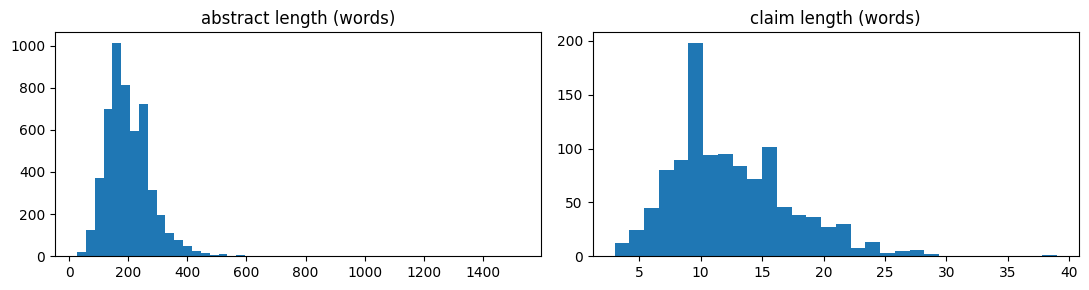

In [4]:
def read_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]

corpus = read_jsonl(os.path.join(DATA_DIR, "corpus.jsonl"))
claims = {s: read_jsonl(os.path.join(DATA_DIR, f"{s}_claims.jsonl")) for s in ["train", "val", "eval"]}

DOC_IDS = [int(d["doc_id"]) for d in corpus]
DOC_INDEX = {d: i for i, d in enumerate(DOC_IDS)}
DOC_TITLE = {int(d["doc_id"]): d["title"].strip() for d in corpus}
DOC_ABS = {int(d["doc_id"]): " ".join(s.strip() for s in d["abstract"]) for d in corpus}
DOC_TEXT = {d: (DOC_TITLE[d] + " " + DOC_ABS[d]).strip() for d in DOC_IDS}
N_DOCS = len(DOC_IDS)

QIDS = {s: [int(c["id"]) for c in claims[s]] for s in claims}
QTEXT = {int(c["id"]): c["claim"].strip() for s in claims for c in claims[s]}
GOLD = {}          # split -> qid -> set(doc_id)        (retrieval qrels; label-agnostic)
GOLD_TRIPLES = {}  # split -> set((qid, doc_id, label))
for s in ["train", "val"]:
    GOLD[s], GOLD_TRIPLES[s] = {}, set()
    for c in claims[s]:
        q = int(c["id"])
        GOLD[s][q] = {int(e["doc_id"]) for e in c["evidence"]}
        for e in c["evidence"]:
            GOLD_TRIPLES[s].add((q, int(e["doc_id"]), e["label"].upper()))

assert len(set(QIDS["train"]) & set(QIDS["val"])) == 0 and len(set(QIDS["val"]) & set(QIDS["eval"])) == 0
print(f"corpus: {N_DOCS} abstracts | claims: " + ", ".join(f"{s}={len(QIDS[s])}" for s in QIDS))
abs_words = np.array([len(DOC_ABS[d].split()) for d in DOC_IDS])
n_sent = np.array([len(d["abstract"]) for d in corpus])
print(f"abstract length (words): mean {abs_words.mean():.0f}, median {np.median(abs_words):.0f}, max {abs_words.max()} | sentences/abstract: mean {n_sent.mean():.1f}")
for s in ["train", "val"]:
    n_gold = Counter(len(GOLD[s][q]) for q in QIDS[s])
    labs = Counter(l for _, _, l in GOLD_TRIPLES[s])
    print(f"{s:5s}: NEI claims={n_gold[0]} ({n_gold[0]/len(QIDS[s]):.0%}) | #gold docs per claim {dict(sorted(n_gold.items()))} | evidence labels {dict(labs)}")
cl_words = np.array([len(QTEXT[q].split()) for s in QIDS for q in QIDS[s]])
print(f"claim length (words): mean {cl_words.mean():.1f}, max {cl_words.max()}")
gold_docs_all = set().union(*[g for s in GOLD for g in GOLD[s].values()])
print(f"distinct abstracts that are gold for some train/val claim: {len(gold_docs_all)} ({len(gold_docs_all)/N_DOCS:.1%} of corpus) -> most of the corpus is distractors")
shared = sum(1 for d in GOLD['val'].values() for x in d if any(x in g for g in GOLD['train'].values()))
print(f"val gold (claim,doc) pairs whose doc is also gold for a train claim: {shared}")
print("\nexample claims:")
for s in ["train", "val", "eval"]:
    print(f"  [{s}] {QTEXT[QIDS[s][3]]}")
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(11, 3))
    ax[0].hist(abs_words, bins=50); ax[0].set_title("abstract length (words)")
    ax[1].hist(cl_words, bins=30); ax[1].set_title("claim length (words)")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("plot skipped:", e)

## Shared utilities — metrics, run construction, TREC writing, format checks

In [5]:
def ndcg_at_k(ranked, gold, k=10):
    dcg = sum(1.0 / math.log2(i + 2) for i, d in enumerate(ranked[:k]) if d in gold)
    idcg = sum(1.0 / math.log2(i + 2) for i in range(min(len(gold), k)))
    return dcg / idcg if idcg > 0 else 0.0

def per_claim_ndcg(run, split, k=10):
    return {q: ndcg_at_k(run[q][0], GOLD[split][q], k) for q in QIDS[split] if GOLD[split][q]}

def evaluate(run, split):
    """nDCG@10, Recall@100, MRR over claims with >= 1 gold abstract (as in the official scoring)."""
    nd, rc, mrr = [], [], []
    for q in QIDS[split]:
        g = GOLD[split][q]
        if not g:
            continue
        docs = run[q][0][:TOP_K]
        nd.append(ndcg_at_k(docs, g, 10))
        rc.append(len(g & set(docs)) / len(g))
        rr = 0.0
        for i, d in enumerate(docs):
            if d in g:
                rr = 1.0 / (i + 1); break
        mrr.append(rr)
    return {"nDCG@10": float(np.mean(nd)), "R@100": float(np.mean(rc)), "MRR": float(np.mean(mrr))}

def run_from_scores(S, qids, k=TOP_K):
    """S: (n_queries x N_DOCS) score matrix (columns follow DOC_IDS). Returns {qid: (doc_ids, scores)}."""
    S = np.asarray(S, dtype=np.float64)
    order = np.argsort(-S, axis=1, kind="stable")[:, :k]
    return {q: ([DOC_IDS[j] for j in order[i]], S[i, order[i]].copy()) for i, q in enumerate(qids)}

def write_trec(path, run, run_name, qids):
    with open(path, "w") as f:
        for q in qids:
            docs, scores = run[q]
            docs, scores = list(docs)[:TOP_K], np.asarray(scores, dtype=np.float64)[:TOP_K]
            assert len(docs) == TOP_K and len(set(docs)) == TOP_K, f"{run_name}: claim {q} needs {TOP_K} unique docs"
            assert np.all(np.diff(scores) <= 1e-12), f"{run_name}: scores increase with rank for claim {q}"
            for r, (d, s) in enumerate(zip(docs, scores), 1):
                f.write(f"{int(q)} Q0 {int(d)} {r} {s:.6f} {run_name}\n")

# official checker as a module (used to validate every file as soon as it is written)
CF = None
if CHECK_FORMAT_PY:
    _spec = importlib.util.spec_from_file_location("check_format", CHECK_FORMAT_PY)
    CF = importlib.util.module_from_spec(_spec); _spec.loader.exec_module(CF)
DOCSET = set(DOC_IDS)

def check_trec_file(path, split):
    if CF is None:
        return
    CF.check_trec(path, set(QIDS[split]), DOCSET)
    print(f"   format OK: {os.path.basename(path)}")

RUNS = defaultdict(dict)      # RUNS[system][split] = run
SCORES = defaultdict(dict)    # SCORES[system][split] = full score matrix (n_q x N_DOCS)
VAL = {}                      # VAL[system] = metrics on validation
RESULTS_EXTRA = {}

def show_table(systems):
    rows = [{"system": s, **{k: round(v, 4) for k, v in VAL[s].items()}} for s in systems if s in VAL]
    print(pd.DataFrame(rows).to_string(index=False))

## Task 1 — BM25 (own sparse implementation), tuned on the validation split

In [6]:

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
try:
    from nltk.stem import PorterStemmer
    _stemmer = PorterStemmer()
except Exception:
    _stemmer = None
    print("nltk not available -> stemming disabled in the grid")

TOKEN_RE = re.compile(r"\w+", re.UNICODE)
_stem_cache = {}
def stem(w):
    if w not in _stem_cache:
        _stem_cache[w] = _stemmer.stem(w) if _stemmer else w
    return _stem_cache[w]

def tokenize(text, use_stem):
    toks = [t for t in TOKEN_RE.findall(text.lower()) if t not in ENGLISH_STOP_WORDS]
    return [stem(t) for t in toks] if use_stem else toks

class BM25:
    def __init__(self, doc_tokens):
        self.vocab = {}
        rows, cols, vals = [], [], []
        for i, toks in enumerate(doc_tokens):
            for t, c in Counter(toks).items():
                j = self.vocab.setdefault(t, len(self.vocab))
                rows.append(i); cols.append(j); vals.append(c)
        self.tf = sp.csr_matrix((np.array(vals, dtype=np.float32), (rows, cols)), shape=(len(doc_tokens), len(self.vocab)))
        self.dl = np.asarray(self.tf.sum(1)).ravel()
        self.avgdl = self.dl.mean()
        df = np.bincount(self.tf.indices, minlength=len(self.vocab))
        n = len(doc_tokens)
        self.idf = np.log(1.0 + (n - df + 0.5) / (df + 0.5)).astype(np.float32)   # Lucene-style, always > 0

    def set_params(self, k1, b):
        tf = self.tf.tocoo()
        norm = k1 * (1 - b + b * self.dl[tf.row] / self.avgdl)
        w = self.idf[tf.col] * tf.data * (k1 + 1) / (tf.data + norm)
        self.W = sp.csr_matrix((w.astype(np.float32), (tf.row, tf.col)), shape=self.tf.shape).T.tocsr()  # V x N
        return self

    def query_matrix(self, token_lists):
        rows, cols, vals = [], [], []
        for i, toks in enumerate(token_lists):
            for t, c in Counter(toks).items():
                if t in self.vocab:
                    rows.append(i); cols.append(self.vocab[t]); vals.append(c)
        return sp.csr_matrix((np.array(vals, dtype=np.float32), (rows, cols)), shape=(len(token_lists), len(self.vocab)))

    def score(self, token_lists):
        return (self.query_matrix(token_lists) @ self.W).toarray()

bm25_grid = []
indexes = {}
for use_stem in ([False, True] if _stemmer else [False]):
    doc_toks = [tokenize(DOC_TEXT[d], use_stem) for d in DOC_IDS]
    idx = BM25(doc_toks)
    indexes[use_stem] = idx
    val_q = [tokenize(QTEXT[q], use_stem) for q in QIDS["val"]]
    for k1 in [0.5, 0.75, 0.9, 1.2, 1.5, 2.0]:
        for b in [0.3, 0.5, 0.6, 0.75, 0.9, 1.0]:
            idx.set_params(k1, b)
            m = evaluate(run_from_scores(idx.score(val_q), QIDS["val"]), "val")
            bm25_grid.append({"stem": use_stem, "k1": k1, "b": b, **m})
grid_df = pd.DataFrame(bm25_grid).sort_values("nDCG@10", ascending=False, kind="stable")
print("BM25 grid search on validation (top 10 of", len(grid_df), "configs):")
print(grid_df.head(10).to_string(index=False))
best_bm25 = grid_df.iloc[0]
BM25_STEM, BM25_K1, BM25_B = bool(best_bm25["stem"]), float(best_bm25["k1"]), float(best_bm25["b"])
bm25 = indexes[BM25_STEM].set_params(BM25_K1, BM25_B)
del indexes
BM25_SETTINGS = (f"Okapi BM25 (own scipy implementation), k1={BM25_K1}, b={BM25_B}, idf=log(1+(N-df+0.5)/(df+0.5)); "
                 f"doc = title + abstract; lowercase \\w+ tokens, sklearn English stop-words removed, Porter stemming={'on' if BM25_STEM else 'off'}; "
                 f"grid k1 x b x stemming ({len(grid_df)} configs) tuned on val nDCG@10")
print("\nchosen:", BM25_SETTINGS)

for s in ["train", "val", "eval"]:
    SCORES["bm25"][s] = bm25.score([tokenize(QTEXT[q], BM25_STEM) for q in QIDS[s]])
    RUNS["bm25"][s] = run_from_scores(SCORES["bm25"][s], QIDS[s])
VAL["bm25"] = evaluate(RUNS["bm25"]["val"], "val")

# BM25 per-query latency on eval claims (tokenise + sparse scoring + top-100)
lat = []
for q in QIDS["eval"]:
    t0 = time.perf_counter()
    sc = bm25.score([tokenize(QTEXT[q], BM25_STEM)])[0]
    np.argpartition(-sc, TOP_K)[:TOP_K]
    lat.append(time.perf_counter() - t0)
BM25_LAT_MS = 1000 * float(np.mean(lat))
print(f"BM25 val: {VAL['bm25']} | query latency {BM25_LAT_MS:.2f} ms")

write_trec(os.path.join(PRED_DIR, "t1_bm25.trec"), RUNS["bm25"]["eval"], "t1_bm25", QIDS["eval"]); check_trec_file(os.path.join(PRED_DIR, "t1_bm25.trec"), "eval")
write_trec(os.path.join(PRED_DIR, "val_bm25.trec"), RUNS["bm25"]["val"], "val_bm25", QIDS["val"]); check_trec_file(os.path.join(PRED_DIR, "val_bm25.trec"), "val")

BM25 grid search on validation (top 10 of 72 configs):
 stem   k1   b  nDCG@10    R@100      MRR
 True 1.20 0.3 0.868012 0.981132 0.850261
 True 0.90 0.3 0.864619 0.981132 0.844919
 True 0.75 0.3 0.864289 0.981132 0.844768
 True 0.90 0.5 0.861413 0.981132 0.839800
 True 0.75 0.5 0.860906 0.990566 0.839726
 True 1.20 0.5 0.860542 0.981132 0.838718
 True 0.50 0.3 0.860104 0.981132 0.843851
 True 0.90 0.6 0.856696 0.990566 0.833607
 True 0.90 0.9 0.856128 0.990566 0.833100
 True 0.75 0.9 0.856050 0.990566 0.833323

chosen: Okapi BM25 (own scipy implementation), k1=1.2, b=0.3, idf=log(1+(N-df+0.5)/(df+0.5)); doc = title + abstract; lowercase \w+ tokens, sklearn English stop-words removed, Porter stemming=on; grid k1 x b x stemming (72 configs) tuned on val nDCG@10
BM25 val: {'nDCG@10': 0.868011903711941, 'R@100': 0.9811320754716981, 'MRR': 0.8502611757201868} | query latency 0.39 ms
   format OK: t1_bm25.trec
   format OK: val_bm25.trec


## Task 2 — Dense retrieval: general (bge-base-en-v1.5) and biomedical (MedCPT)

In [7]:
def model_path(name):
    return MODEL_PATH_OVERRIDES.get(name, name)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def load_encoder(name, cls=AutoModel):
    tok = AutoTokenizer.from_pretrained(model_path(name))
    model = cls.from_pretrained(model_path(name))
    n = count_params(model)
    assert n <= MAX_PARAMS, f"{name} has {n/1e6:.0f}M parameters > 400M limit"
    print(f"   loaded {name}: {n/1e6:.1f}M parameters")
    return tok, model.float().to(DEVICE).eval()

def pool(out, attn, pooling):
    h = out.last_hidden_state
    if pooling == "cls":
        return h[:, 0]
    m = attn.unsqueeze(-1).to(h.dtype)
    return (h * m).sum(1) / m.sum(1).clamp(min=1e-9)

def encode(model, tok, texts, max_len, pooling="cls", normalize=False, batch_size=64, pairs=None, to_cpu=True):
    """Embed texts (optionally text pairs, e.g. MedCPT [title, abstract]). Length-sorted batching."""
    lens = np.array([len(t) + (len(pairs[i]) if pairs is not None else 0) for i, t in enumerate(texts)])
    order = np.argsort(-lens, kind="stable")
    embs = [None] * len(texts)
    with torch.inference_mode(), autocast_ctx():
        for st in range(0, len(texts), batch_size):
            idx = order[st:st + batch_size]
            a = [texts[i] for i in idx]
            b = [pairs[i] for i in idx] if pairs is not None else None
            enc = tok(a, b, padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(DEVICE)
            e = pool(model(**enc), enc["attention_mask"], pooling).float()
            if normalize:
                e = F.normalize(e, dim=-1)
            for j, i in enumerate(idx):
                embs[i] = e[j]
    E = torch.stack(embs)
    return E.cpu() if to_cpu else E

DENSE_SPECS = {
    "general": dict(q_model=GENERAL_MODEL, d_model=GENERAL_MODEL, pooling="cls", normalize=True,
                    q_prefix=BGE_QUERY_INSTRUCTION, q_maxlen=128, d_maxlen=512, doc_input="text"),
    "scientific": dict(q_model=SCI_QUERY_MODEL, d_model=SCI_DOC_MODEL, pooling="cls", normalize=False,
                       q_prefix="", q_maxlen=64, d_maxlen=512, doc_input="pair"),
}

def doc_inputs(spec):
    if spec["doc_input"] == "pair":
        return [DOC_TITLE[d] for d in DOC_IDS], [DOC_ABS[d] for d in DOC_IDS]
    return [DOC_TEXT[d] for d in DOC_IDS], None

def proc_mem_mb():
    try:
        import psutil
        return psutil.Process().memory_info().rss / 2**20
    except Exception:
        return float("nan")

DENSE_STATS = {}
def run_dense(key, spec, splits=("train", "val", "eval")):
    free_memory()
    if CUDA:
        torch.cuda.reset_peak_memory_stats(DEVICE)
    mem0 = proc_mem_mb()
    d_tok, d_model = load_encoder(spec["d_model"])
    if spec["q_model"] == spec["d_model"]:
        q_tok, q_model = d_tok, d_model
    else:
        q_tok, q_model = load_encoder(spec["q_model"])
    texts, pairs = doc_inputs(spec)
    sync(); t0 = time.perf_counter()
    D = encode(d_model, d_tok, texts, spec["d_maxlen"], spec["pooling"], spec["normalize"], 64, pairs, to_cpu=False)
    sync(); index_time = time.perf_counter() - t0
    peak_mb = torch.cuda.max_memory_allocated(DEVICE) / 2**20 if CUDA else proc_mem_mb() - mem0
    index_mb = D.numel() * D.element_size() / 2**20
    for s in splits:
        Q = encode(q_model, q_tok, [spec["q_prefix"] + QTEXT[q] for q in QIDS[s]], spec["q_maxlen"], spec["pooling"], spec["normalize"], 128, to_cpu=False)
        SCORES[key][s] = (Q @ D.T).float().cpu().numpy()
        RUNS[key][s] = run_from_scores(SCORES[key][s], QIDS[s])
    # per-query latency: encode one claim + exact search over the GPU index + top-100 (eval claims, after warm-up)
    lat = []
    for i, q in enumerate(QIDS["eval"][:5] + QIDS["eval"]):
        sync(); t0 = time.perf_counter()
        qe = encode(q_model, q_tok, [spec["q_prefix"] + QTEXT[q]], spec["q_maxlen"], spec["pooling"], spec["normalize"], 1, to_cpu=False)
        torch.topk(qe @ D.T, TOP_K, dim=1)
        sync()
        if i >= 5:
            lat.append(time.perf_counter() - t0)
    DENSE_STATS[key] = {"index_time_sec": round(index_time, 2), "query_latency_ms": round(1000 * float(np.mean(lat)), 2),
                        "memory_mb": round(float(peak_mb), 1), "index_size_mb": round(index_mb, 1)}
    VAL[key] = evaluate(RUNS[key]["val"], "val")
    print(f"   {key}: val {VAL[key]} | {DENSE_STATS[key]}")
    del d_model, q_model, D
    free_memory()

GEN_CAND_VAL = {}
for name in GENERAL_CANDIDATES:
    ck = "general::" + name
    print(f"[general candidate: {name}]")
    run_dense(ck, dict(DENSE_SPECS["general"], q_model=name, d_model=name))
    GEN_CAND_VAL[name] = VAL[ck]["nDCG@10"]
GENERAL_MODEL = max(GENERAL_CANDIDATES, key=lambda n: GEN_CAND_VAL[n])
FT_BASE_MODEL = GENERAL_MODEL
DENSE_SPECS["general"] = dict(DENSE_SPECS["general"], q_model=GENERAL_MODEL, d_model=GENERAL_MODEL)
src = "general::" + GENERAL_MODEL
SCORES["general"], RUNS["general"] = SCORES[src], RUNS[src]
VAL["general"], DENSE_STATS["general"] = VAL[src], DENSE_STATS[src]
for name in GENERAL_CANDIDATES:
    SCORES.pop("general::" + name, None); RUNS.pop("general::" + name, None)
print(f"general model chosen on val nDCG@10: {GENERAL_MODEL}  ({ {n.split('/')[-1]: round(v, 4) for n, v in GEN_CAND_VAL.items()} })")
print("[scientific]")
run_dense("scientific", DENSE_SPECS["scientific"])

write_trec(os.path.join(PRED_DIR, "t2_general.trec"), RUNS["general"]["eval"], "t2_general", QIDS["eval"]); check_trec_file(os.path.join(PRED_DIR, "t2_general.trec"), "eval")
write_trec(os.path.join(PRED_DIR, "t2_scientific.trec"), RUNS["scientific"]["eval"], "t2_scientific", QIDS["eval"]); check_trec_file(os.path.join(PRED_DIR, "t2_scientific.trec"), "eval")
write_trec(os.path.join(PRED_DIR, "val_general.trec"), RUNS["general"]["val"], "val_general", QIDS["val"]); check_trec_file(os.path.join(PRED_DIR, "val_general.trec"), "val")
print("memory_mb = peak GPU memory allocated while loading the model(s) and encoding the corpus (weights + activations + fp32 index).")
show_table(["bm25", "general", "scientific"])

[general candidate: BAAI/bge-large-en-v1.5]


config.json:   0%|          | 0.00/779 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

   loaded ncbi/MedCPT-Query-Encoder: 109.5M parameters
   scientific: val {'nDCG@10': 0.8508920087192072, 'R@100': 1.0, 'MRR': 0.8126753749395258} | {'index_time_sec': 24.16, 'query_latency_ms': 11.47, 'memory_mb': 6520.3, 'index_size_mb': 15.2}
   format OK: t2_general.trec
   format OK: t2_scientific.trec
   format OK: val_general.trec
memory_mb = peak GPU memory allocated while loading the model(s) and encoding the corpus (weights + activations + fp32 index).
    system  nDCG@10  R@100    MRR
      bm25   0.8680 0.9811 0.8503
   general   0.9328 1.0000 0.9191
scientific   0.8509 1.0000 0.8127


## Task 3a — Hybrid of BM25 + dense (weighted z-score fusion vs weighted reciprocal-rank fusion)

In [8]:
def zscore(S):
    S = np.asarray(S, dtype=np.float64)
    return (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-9)

def full_ranks(S):
    order = np.argsort(-np.asarray(S), axis=1, kind="stable")
    R = np.empty_like(order)
    rows = np.arange(S.shape[0])[:, None]
    R[rows, order] = np.arange(1, S.shape[1] + 1)[None, :]
    return R

def weight_grid(n, step=0.1, first_min=0.1):
    """weights over n systems summing to 1; first system (BM25) gets >= first_min and the rest >= 0.1 in total."""
    units = int(round(1 / step)); out = []
    def rec(prefix, left):
        if len(prefix) == n - 1:
            out.append(prefix + [left]); return
        for u in range(left + 1):
            rec(prefix + [u], left - u)
    rec([], units)
    return [[u * step for u in w] for w in out if w[0] * step >= first_min - 1e-9 and sum(w[1:]) * step >= 0.1 - 1e-9]

def fuse(systems, weights, split, method, cache):
    if method == "zscore":
        return sum(w * cache[("z", s, split)] for s, w in zip(systems, weights) if w > 0)
    return sum(w / (60.0 + cache[("r", s, split)]) for s, w in zip(systems, weights) if w > 0)

def tune_hybrid(systems, label):
    cache = {}
    for s in systems:
        for sp_ in ["val"]:
            cache[("z", s, sp_)] = zscore(SCORES[s][sp_])
            cache[("r", s, sp_)] = full_ranks(SCORES[s][sp_])
    rows = []
    for method in ["zscore", "rrf"]:
        for w in weight_grid(len(systems)):
            m = evaluate(run_from_scores(fuse(systems, w, "val", method, cache), QIDS["val"]), "val")
            rows.append({"method": method, **{f"w_{s}": round(x, 2) for s, x in zip(systems, w)}, **m})
    df = pd.DataFrame(rows).sort_values("nDCG@10", ascending=False, kind="stable")
    print(f"{label}: best 8 of {len(df)} fusion configs on val")
    print(df.head(8).to_string(index=False))
    best = df.iloc[0]
    weights = [float(best[f"w_{s}"]) for s in systems]
    return best["method"], weights

def apply_hybrid(key, systems, method, weights, splits):
    for s in splits:
        cache = {}
        for sysname in systems:
            if method == "zscore":
                cache[("z", sysname, s)] = zscore(SCORES[sysname][s])
            else:
                cache[("r", sysname, s)] = full_ranks(SCORES[sysname][s])
        SCORES[key][s] = fuse(systems, weights, s, method, cache)
        RUNS[key][s] = run_from_scores(SCORES[key][s], QIDS[s])
    VAL[key] = evaluate(RUNS[key]["val"], "val")

def describe_hybrid(systems, method, weights, names):
    parts = " + ".join(f"{w:.1f}*{names[s]}" for s, w in zip(systems, weights) if w > 0)
    if method == "zscore":
        return f"weighted score interpolation of per-claim z-normalised scores over the full corpus: {parts} (weights grid-searched on val, also compared against weighted RRF)"
    return f"weighted reciprocal rank fusion sum_i w_i/(60+rank_i): {parts} (weights grid-searched on val, also compared against z-score interpolation)"

GEN_SHORT = GENERAL_MODEL.split("/")[-1]
SYS_NAMES = {"bm25": "BM25", "general": GEN_SHORT, "scientific": "MedCPT", "ft_random": GEN_SHORT + "-ft-random", "ft_hard": GEN_SHORT + "-ft-hard"}
HYB_SYSTEMS = ["bm25", "general", "scientific"]
HYB_METHOD, HYB_WEIGHTS = tune_hybrid(HYB_SYSTEMS, "hybrid")
apply_hybrid("hybrid", HYB_SYSTEMS, HYB_METHOD, HYB_WEIGHTS, ["train", "val", "eval"])
HYBRID_DESC = describe_hybrid(HYB_SYSTEMS, HYB_METHOD, HYB_WEIGHTS, SYS_NAMES)
print("\nhybrid:", HYBRID_DESC, "\nval:", VAL["hybrid"])
write_trec(os.path.join(PRED_DIR, "t3_hybrid.trec"), RUNS["hybrid"]["eval"], "t3_hybrid", QIDS["eval"]); check_trec_file(os.path.join(PRED_DIR, "t3_hybrid.trec"), "eval")

hybrid: best 8 of 108 fusion configs on val
method  w_bm25  w_general  w_scientific  nDCG@10  R@100      MRR
zscore     0.1        0.9           0.0 0.938759    1.0 0.927579
zscore     0.1        0.8           0.1 0.937125    1.0 0.922091
   rrf     0.2        0.5           0.3 0.934064    1.0 0.919429
   rrf     0.3        0.5           0.2 0.933050    1.0 0.921734
zscore     0.2        0.8           0.0 0.933005    1.0 0.918041
zscore     0.1        0.7           0.2 0.932148    1.0 0.915523
zscore     0.1        0.5           0.4 0.931923    1.0 0.915881
   rrf     0.1        0.6           0.3 0.931839    1.0 0.915094

hybrid: weighted score interpolation of per-claim z-normalised scores over the full corpus: 0.1*BM25 + 0.9*bge-large-en-v1.5 (weights grid-searched on val, also compared against weighted RRF) 
val: {'nDCG@10': 0.9387591440629203, 'R@100': 1.0, 'MRR': 0.9275786163522012}
   format OK: t3_hybrid.trec


## Task 3b — Cross-encoder reranking of the best first-stage system's top-k

In [9]:
def ce_scores_for(model, tok, qtext, docs, max_len=512, batch_size=32):
    out = []
    with torch.inference_mode(), autocast_ctx():
        for st in range(0, len(docs), batch_size):
            ds = docs[st:st + batch_size]
            enc = tok([qtext] * len(ds), [DOC_TEXT[d] for d in ds], padding=True, truncation=True,
                      max_length=max_len, return_tensors="pt").to(DEVICE)
            logits = model(**enc).logits.float()
            out.append(logits[:, 0] if logits.shape[1] == 1 else torch.log_softmax(logits, -1)[:, -1])
    return torch.cat(out).cpu().numpy().astype(np.float64)

def rerank_run(first_run, ce, k, qids):
    """Top-k of the first stage in cross-encoder order at ranks 1..k, then ranks k+1..100 in first-stage order."""
    out = {}
    for q in qids:
        docs, fs = first_run[q]
        docs, fs = list(docs[:TOP_K]), np.asarray(fs[:TOP_K], dtype=np.float64)
        c = ce[q][:k]
        o = np.argsort(-c, kind="stable")
        head_docs = [docs[i] for i in o]
        head_sc = 2.0 + 1.0 / (1.0 + np.exp(-c[o]))            # in (2, 3], non-increasing
        tail_docs = docs[k:]
        tail = fs[k:]
        tail_sc = (tail - tail.min()) / (tail.max() - tail.min() + 1e-12) if len(tail) else tail   # in [0, 1], order kept
        out[q] = (head_docs + tail_docs, np.concatenate([head_sc, tail_sc]))
        assert len(set(out[q][0])) == TOP_K
    return out

def score_topk_with_ce(model, tok, first_run, qids, k, timed=False):
    ce, lat = {}, []
    for i, q in enumerate(qids):
        sync(); t0 = time.perf_counter()
        ce[q] = ce_scores_for(model, tok, QTEXT[q], list(first_run[q][0][:k]))
        sync(); lat.append(time.perf_counter() - t0)
    return ce, 1000 * float(np.mean(lat[3:] if len(lat) > 3 else lat))

def tune_rerank(first_key, candidates):
    rows, ce_val = [], {}
    for name in candidates:
        free_memory()
        tok, model = load_encoder(name, AutoModelForSequenceClassification)
        ce_val[name], _ = score_topk_with_ce(model, tok, RUNS[first_key]["val"], QIDS["val"], TOP_K)
        for k in RERANK_K_GRID:
            m = evaluate(rerank_run(RUNS[first_key]["val"], ce_val[name], k, QIDS["val"]), "val")
            rows.append({"reranker": name, "k": k, **m})
        del model; free_memory()
    df = pd.DataFrame(rows).sort_values("nDCG@10", ascending=False, kind="stable")
    print(df.to_string(index=False))
    best = df.iloc[0]
    return best["reranker"], int(best["k"]), ce_val[best["reranker"]], df

FIRST_STAGE = max(["bm25", "general", "scientific", "hybrid"], key=lambda s: VAL[s]["nDCG@10"])
print("best first-stage system on val:", FIRST_STAGE, VAL[FIRST_STAGE])
RERANKER, RERANK_K, ce_val_best, rerank_df = tune_rerank(FIRST_STAGE, RERANKER_CANDIDATES)
RUNS["rerank"]["val"] = rerank_run(RUNS[FIRST_STAGE]["val"], ce_val_best, RERANK_K, QIDS["val"])
VAL["rerank"] = evaluate(RUNS["rerank"]["val"], "val")

free_memory()
ce_tok, ce_model = load_encoder(RERANKER, AutoModelForSequenceClassification)
ce_eval, RERANK_LAT_MS = score_topk_with_ce(ce_model, ce_tok, RUNS[FIRST_STAGE]["eval"], QIDS["eval"], RERANK_K, timed=True)
RUNS["rerank"]["eval"] = rerank_run(RUNS[FIRST_STAGE]["eval"], ce_eval, RERANK_K, QIDS["eval"])
print(f"\nrerank: {RERANKER} on top-{RERANK_K} of {FIRST_STAGE} | val {VAL['rerank']} | cross-encoder latency {RERANK_LAT_MS:.1f} ms/claim")
write_trec(os.path.join(PRED_DIR, "t3_rerank.trec"), RUNS["rerank"]["eval"], "t3_rerank", QIDS["eval"]); check_trec_file(os.path.join(PRED_DIR, "t3_rerank.trec"), "eval")
show_table(["bm25", "general", "scientific", "hybrid", "rerank"])

best first-stage system on val: hybrid {'nDCG@10': 0.9387591440629203, 'R@100': 1.0, 'MRR': 0.9275786163522012}


config.json:   0%|          | 0.00/799 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/443 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

                 reranker   k  nDCG@10  R@100      MRR
ncbi/MedCPT-Cross-Encoder  10 0.914860    1.0 0.890629
ncbi/MedCPT-Cross-Encoder  30 0.912865    1.0 0.886635
ncbi/MedCPT-Cross-Encoder  50 0.912523    1.0 0.886321
ncbi/MedCPT-Cross-Encoder 100 0.912523    1.0 0.886321
ncbi/MedCPT-Cross-Encoder  20 0.911100    1.0 0.885912
   BAAI/bge-reranker-base  10 0.873740    1.0 0.836148
   BAAI/bge-reranker-base  20 0.858058    1.0 0.827537
   BAAI/bge-reranker-base  30 0.853988    1.0 0.825349
   BAAI/bge-reranker-base  50 0.851126    1.0 0.822684
   BAAI/bge-reranker-base 100 0.848002    1.0 0.821870


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

   loaded ncbi/MedCPT-Cross-Encoder: 109.5M parameters

rerank: ncbi/MedCPT-Cross-Encoder on top-10 of hybrid | val {'nDCG@10': 0.9148600831787288, 'R@100': 1.0, 'MRR': 0.8906289308176101} | cross-encoder latency 72.2 ms/claim
   format OK: t3_rerank.trec
    system  nDCG@10  R@100    MRR
      bm25   0.8680 0.9811 0.8503
   general   0.9328 1.0000 0.9191
scientific   0.8509 1.0000 0.8127
    hybrid   0.9388 1.0000 0.9276
    rerank   0.9149 1.0000 0.8906


## Task 4 — Fine-tune the bi-encoder on training claims: random negatives vs hard negatives
Contrastive loss (InfoNCE, temperature 0.02) with in-batch negatives + one explicit negative per pair; columns that are gold for the row's claim are masked (no false in-batch negatives). Validation nDCG@10 and train nDCG@10 are measured after every epoch to detect over-fitting; the best-validation epoch is kept.

In [10]:
TRAIN_PAIRS = [(q, d) for q in QIDS["train"] for d in sorted(GOLD["train"][q])]
print("training (claim, gold abstract) pairs:", len(TRAIN_PAIRS), "from", sum(1 for q in QIDS["train"] if GOLD["train"][q]), "claims")

HARD_POOL = {}
for q in QIDS["train"]:
    pool_ = []
    for s in ["bm25", "general", "scientific"]:
        pool_ += [d for d in RUNS[s]["train"][q][0][:FT_HARD_POOL_DEPTH] if d not in GOLD["train"][q] and d not in pool_]
    HARD_POOL[q] = pool_
print("mean hard-negative pool size:", np.mean([len(HARD_POOL[q]) for q, _ in TRAIN_PAIRS]).round(1))

FT_SPEC = dict(DENSE_SPECS["general"])

def embed_train(model, tok, texts, max_len):
    enc = tok(texts, padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(DEVICE)
    return F.normalize(pool(model(**enc), enc["attention_mask"], "cls").float(), dim=-1)

def score_splits_with(model, tok, splits):
    model.eval()
    texts, _ = doc_inputs(FT_SPEC)
    D = encode(model, tok, texts, FT_SPEC["d_maxlen"], "cls", True, 64, to_cpu=False)
    out = {}
    for s in splits:
        Q = encode(model, tok, [FT_SPEC["q_prefix"] + QTEXT[q] for q in QIDS[s]], FT_SPEC["q_maxlen"], "cls", True, 128, to_cpu=False)
        out[s] = (Q @ D.T).float().cpu().numpy()
    del D
    return out

def linear_warmup(step, total, warm):
    return (step + 1) / max(1, warm) if step < warm else max(0.0, (total - step) / max(1, total - warm))

def train_biencoder(neg_mode, key):
    set_seed(SEED)
    free_memory()
    tok, model = load_encoder(FT_BASE_MODEL)
    try:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    except Exception:
        model.gradient_checkpointing_enable()
    rng = random.Random(SEED)
    opt = torch.optim.AdamW(model.parameters(), lr=FT_LR, weight_decay=0.01)
    steps_per_epoch = math.ceil(len(TRAIN_PAIRS) / FT_BATCH)
    total = steps_per_epoch * FT_EPOCHS
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda st: linear_warmup(st, total, int(0.1 * total)))
    scaler = torch.amp.GradScaler("cuda", enabled=CUDA)
    history, best, best_state = [], -1.0, None
    sc0 = score_splits_with(model, tok, ["val", "train"])
    history.append({"epoch": 0, "train_loss": None,
                    "train_nDCG@10": evaluate(run_from_scores(sc0["train"], QIDS["train"]), "train")["nDCG@10"],
                    "val_nDCG@10": evaluate(run_from_scores(sc0["val"], QIDS["val"]), "val")["nDCG@10"]})
    print(f"   [{neg_mode}] epoch 0 (pretrained): train nDCG@10 {history[0]['train_nDCG@10']:.4f} | val nDCG@10 {history[0]['val_nDCG@10']:.4f}")
    step = 0
    for ep in range(1, FT_EPOCHS + 1):
        model.train()
        data = TRAIN_PAIRS[:]; rng.shuffle(data)
        losses = []
        for st in range(0, len(data), FT_BATCH):
            batch = data[st:st + FT_BATCH]
            qs = [q for q, _ in batch]; pos = [d for _, d in batch]
            negs = []
            for q, _ in batch:
                if neg_mode == "hard" and HARD_POOL[q]:
                    negs.append(rng.choice(HARD_POOL[q]))
                else:
                    while True:
                        d = DOC_IDS[rng.randrange(N_DOCS)]
                        if d not in GOLD["train"][q]:
                            break
                    negs.append(d)
            cols = pos + negs
            with autocast_ctx():
                qe = embed_train(model, tok, [FT_SPEC["q_prefix"] + QTEXT[q] for q in qs], FT_SPEC["q_maxlen"])
                de = embed_train(model, tok, [DOC_TEXT[d] for d in cols], FT_SPEC["d_maxlen"])
            sim = (qe.float() @ de.float().T) / FT_TEMPERATURE
            mask = torch.zeros_like(sim, dtype=torch.bool)
            for i, q in enumerate(qs):
                for j, d in enumerate(cols):
                    if j != i and d in GOLD["train"][q]:
                        mask[i, j] = True
            sim = sim.masked_fill(mask, -1e4)
            loss = F.cross_entropy(sim, torch.arange(len(qs), device=sim.device))
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); step += 1
            losses.append(loss.item())
        sc = score_splits_with(model, tok, ["val", "train"])
        h = {"epoch": ep, "train_loss": float(np.mean(losses)),
             "train_nDCG@10": evaluate(run_from_scores(sc["train"], QIDS["train"]), "train")["nDCG@10"],
             "val_nDCG@10": evaluate(run_from_scores(sc["val"], QIDS["val"]), "val")["nDCG@10"]}
        history.append(h)
        print(f"   [{neg_mode}] epoch {ep}: loss {h['train_loss']:.4f} | train nDCG@10 {h['train_nDCG@10']:.4f} | val nDCG@10 {h['val_nDCG@10']:.4f}")
        if h["val_nDCG@10"] > best:
            best = h["val_nDCG@10"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    best_epoch = max(history[1:], key=lambda r: r["val_nDCG@10"])["epoch"]
    model.load_state_dict(best_state)
    sc = score_splits_with(model, tok, ["val", "eval"])
    for s in ["val", "eval"]:
        SCORES[key][s] = sc[s]
        RUNS[key][s] = run_from_scores(sc[s], QIDS[s])
    VAL[key] = evaluate(RUNS[key]["val"], "val")
    print(f"   [{neg_mode}] kept epoch {best_epoch} (best val nDCG@10) -> val {VAL[key]}")
    del model, best_state; free_memory()
    return pd.DataFrame(history), best_epoch

FT_HIST, FT_BEST_EPOCH = {}, {}
for mode, key in [("random", "ft_random"), ("hard", "ft_hard")]:
    FT_HIST[mode], FT_BEST_EPOCH[mode] = train_biencoder(mode, key)

write_trec(os.path.join(PRED_DIR, "t4_random.trec"), RUNS["ft_random"]["eval"], "t4_random", QIDS["eval"]); check_trec_file(os.path.join(PRED_DIR, "t4_random.trec"), "eval")
write_trec(os.path.join(PRED_DIR, "t4_hard.trec"), RUNS["ft_hard"]["eval"], "t4_hard", QIDS["eval"]); check_trec_file(os.path.join(PRED_DIR, "t4_hard.trec"), "eval")
for mode in FT_HIST:
    print(f"\n{mode} negatives - per-epoch history:\n" + FT_HIST[mode].round(4).to_string(index=False))

training (claim, gold abstract) pairs: 440 from 399 claims
mean hard-negative pool size: 59.9


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

   loaded BAAI/bge-large-en-v1.5: 335.1M parameters
   [random] epoch 0 (pretrained): train nDCG@10 0.9213 | val nDCG@10 0.9328
   [random] epoch 1: loss 0.0294 | train nDCG@10 0.9513 | val nDCG@10 0.9143
   [random] epoch 2: loss 0.0020 | train nDCG@10 0.9620 | val nDCG@10 0.9169
   [random] epoch 3: loss 0.0095 | train nDCG@10 0.9701 | val nDCG@10 0.9148
   [random] epoch 4: loss 0.0017 | train nDCG@10 0.9704 | val nDCG@10 0.9108
   [random] kept epoch 2 (best val nDCG@10) -> val {'nDCG@10': 0.9169043556467961, 'R@100': 0.9905660377358491, 'MRR': 0.9006813417190775}


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

   loaded BAAI/bge-large-en-v1.5: 335.1M parameters
   [hard] epoch 0 (pretrained): train nDCG@10 0.9213 | val nDCG@10 0.9328
   [hard] epoch 1: loss 0.0572 | train nDCG@10 0.9623 | val nDCG@10 0.9173
   [hard] epoch 2: loss 0.0169 | train nDCG@10 0.9842 | val nDCG@10 0.9303
   [hard] epoch 3: loss 0.0068 | train nDCG@10 0.9860 | val nDCG@10 0.9298
   [hard] epoch 4: loss 0.0023 | train nDCG@10 0.9850 | val nDCG@10 0.9294
   [hard] kept epoch 2 (best val nDCG@10) -> val {'nDCG@10': 0.9302671790790167, 'R@100': 1.0, 'MRR': 0.9107573375262055}
   format OK: t4_random.trec
   format OK: t4_hard.trec

random negatives - per-epoch history:
 epoch  train_loss  train_nDCG@10  val_nDCG@10
     0         NaN         0.9213       0.9328
     1      0.0294         0.9513       0.9143
     2      0.0020         0.9620       0.9169
     3      0.0095         0.9701       0.9148
     4      0.0017         0.9704       0.9108

hard negatives - per-epoch history:
 epoch  train_loss  train_nDCG@10  val

### Ablation table (validation) — the seven submitted runs

In [11]:
ABLATION = ["bm25", "general", "scientific", "hybrid", "rerank", "ft_random", "ft_hard"]
show_table(ABLATION)

    system  nDCG@10  R@100    MRR
      bm25   0.8680 0.9811 0.8503
   general   0.9328 1.0000 0.9191
scientific   0.8509 1.0000 0.8127
    hybrid   0.9388 1.0000 0.9276
    rerank   0.9149 1.0000 0.8906
 ft_random   0.9169 0.9906 0.9007
   ft_hard   0.9303 1.0000 0.9108


## Task 5a — Pick the best retriever for verification
Candidates: the seven runs above plus one extra combination built from them (hybrid of BM25 + MedCPT + best fine-tuned model, reranked with the chosen cross-encoder). The one with the highest validation nDCG@10 is used.

In [12]:
FT_BEST = max(["ft_random", "ft_hard"], key=lambda s: VAL[s]["nDCG@10"])
H2_SYSTEMS = ["bm25", "scientific", FT_BEST]
H2_METHOD, H2_WEIGHTS = tune_hybrid(H2_SYSTEMS, "hybrid incl. fine-tuned")
apply_hybrid("hybrid_ft", H2_SYSTEMS, H2_METHOD, H2_WEIGHTS, ["val", "eval"])
ce_val_h2, _ = score_topk_with_ce(ce_model, ce_tok, RUNS["hybrid_ft"]["val"], QIDS["val"], TOP_K)
k_rows = [(k, evaluate(rerank_run(RUNS["hybrid_ft"]["val"], ce_val_h2, k, QIDS["val"]), "val")["nDCG@10"]) for k in RERANK_K_GRID]
H2_K = max(k_rows, key=lambda r: r[1])[0]
RUNS["hybrid_ft_rerank"]["val"] = rerank_run(RUNS["hybrid_ft"]["val"], ce_val_h2, H2_K, QIDS["val"])
VAL["hybrid_ft_rerank"] = evaluate(RUNS["hybrid_ft_rerank"]["val"], "val")
print("hybrid_ft:", VAL["hybrid_ft"], "| + rerank (k=%d):" % H2_K, VAL["hybrid_ft_rerank"])

CANDIDATE_RETRIEVERS = ABLATION + ["hybrid_ft", "hybrid_ft_rerank"]
BEST_RETRIEVER = max(CANDIDATE_RETRIEVERS, key=lambda s: VAL[s]["nDCG@10"])
if BEST_RETRIEVER == "hybrid_ft_rerank":
    ce_eval_h2, _ = score_topk_with_ce(ce_model, ce_tok, RUNS["hybrid_ft"]["eval"], QIDS["eval"], H2_K)
    RUNS["hybrid_ft_rerank"]["eval"] = rerank_run(RUNS["hybrid_ft"]["eval"], ce_eval_h2, H2_K, QIDS["eval"])
show_table(CANDIDATE_RETRIEVERS)

def retriever_description(s):
    d = {
        "bm25": "t1_bm25 (BM25)", "general": f"t2_general ({GENERAL_MODEL})", "scientific": "t2_scientific (MedCPT query/article encoders)",
        "hybrid": f"t3_hybrid ({HYBRID_DESC})",
        "rerank": f"t3_rerank ({RERANKER} reranking top-{RERANK_K} of {FIRST_STAGE})",
        "ft_random": f"t4_random ({GEN_SHORT} fine-tuned, random negatives)", "ft_hard": f"t4_hard ({GEN_SHORT} fine-tuned, hard negatives)",
        "hybrid_ft": "hybrid " + describe_hybrid(H2_SYSTEMS, H2_METHOD, H2_WEIGHTS, SYS_NAMES),
        "hybrid_ft_rerank": f"{RERANKER} reranking top-{H2_K} of a hybrid of BM25 + MedCPT + {SYS_NAMES[FT_BEST]} (" + describe_hybrid(H2_SYSTEMS, H2_METHOD, H2_WEIGHTS, SYS_NAMES) + ")",
    }
    return d[s]
print("\nretriever used for verification:", BEST_RETRIEVER, "->", retriever_description(BEST_RETRIEVER))
del ce_model; free_memory()

hybrid incl. fine-tuned: best 8 of 108 fusion configs on val
method  w_bm25  w_scientific  w_ft_hard  nDCG@10    R@100      MRR
zscore     0.2           0.1        0.7 0.945219 1.000000 0.932883
zscore     0.2           0.0        0.8 0.944411 0.990566 0.933438
zscore     0.2           0.2        0.6 0.943734 1.000000 0.932033
zscore     0.1           0.3        0.6 0.942927 1.000000 0.930978
zscore     0.2           0.3        0.5 0.942280 1.000000 0.930011
zscore     0.1           0.5        0.4 0.941021 1.000000 0.930251
zscore     0.1           0.4        0.5 0.938762 1.000000 0.926604
zscore     0.1           0.2        0.7 0.938686 1.000000 0.921296
hybrid_ft: {'nDCG@10': 0.9452193618453032, 'R@100': 1.0, 'MRR': 0.932883380168607} | + rerank (k=10): {'nDCG@10': 0.9147244101827746, 'R@100': 1.0, 'MRR': 0.8903519336277265}
          system  nDCG@10  R@100    MRR
            bm25   0.8680 0.9811 0.8503
         general   0.9328 1.0000 0.9191
      scientific   0.8509 1.0000 0.8127
 

## Task 5b — Claim verification with an NLI cross-encoder (zero-shot vs fine-tuned on training claims)
premise = abstract (title + text), hypothesis = claim. entailment → SUPPORT, contradiction → CONTRADICT, neutral → NEI. For each claim the top-K retrieved abstracts are scored; an abstract is kept if max(P(entail), P(contradict)) ≥ τ (at most 3 per claim). K, τ, the training epoch and zero-shot vs fine-tuned are chosen on validation F1.

In [13]:
LAB2NAME = {"SUPPORT": "entail", "NEI": "neutral", "CONTRADICT": "contra"}

def nli_label_ids(model):
    id2 = {int(i): str(l).lower() for i, l in model.config.id2label.items()}
    out = {}
    for lab, pref in LAB2NAME.items():
        hits = [i for i, l in id2.items() if l.startswith(pref)]
        assert len(hits) == 1, f"cannot map {lab} in {id2}"
        out[lab] = hits[0]
    return out

def abstract_premise(q, d):
    return DOC_TEXT[d]

def nli_probs(model, tok, pairs, batch_size=32, premise=abstract_premise):
    """pairs: list of (qid, doc_id). Returns array (n, 3) with columns [SUPPORT, NEI, CONTRADICT]."""
    ids = nli_label_ids(model)
    model.eval()
    res = np.zeros((len(pairs), 3))
    prem = [premise(q, d) for q, d in pairs]
    lens = np.array([len(p) for p in prem]); order = np.argsort(-lens, kind="stable")
    with torch.inference_mode(), autocast_ctx():
        for st in range(0, len(pairs), batch_size):
            idx = order[st:st + batch_size]
            enc = tok([prem[i] for i in idx], [QTEXT[pairs[i][0]] for i in idx], padding=True,
                      truncation="only_first", max_length=NLI_MAX_LEN, return_tensors="pt").to(DEVICE)
            p = torch.softmax(model(**enc).logits.float(), -1).cpu().numpy()
            for j, i in enumerate(idx):
                res[i] = [p[j, ids["SUPPORT"]], p[j, ids["NEI"]], p[j, ids["CONTRADICT"]]]
    return res

def candidate_pairs(split, retr=None):
    retr = retr or BEST_RETRIEVER
    return [(q, d) for q in QIDS[split] for d in RUNS[retr][split][q][0][:NLI_CAND_K]]

def decide(pairs, probs, K, tau):
    rank_in_claim = defaultdict(int); per = defaultdict(list)
    for (q, d), p in zip(pairs, probs):
        r = rank_in_claim[q]; rank_in_claim[q] += 1
        if r >= K:
            continue
        conf = max(p[0], p[2])
        if conf >= tau:
            per[q].append((conf, d, "SUPPORT" if p[0] >= p[2] else "CONTRADICT"))
    out = set()
    for q, lst in per.items():
        for conf, d, lab in sorted(lst, key=lambda x: -x[0])[:3]:
            out.add((q, d, lab))
    return out

def prf(pred, gold):
    tp = len(pred & gold)
    p = tp / len(pred) if pred else 0.0
    r = tp / len(gold) if gold else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)

TAUS = [round(float(x), 3) for x in np.arange(0.20, 0.981, 0.02)]
def tune_decision(pairs, probs):
    best = None
    for K in range(1, NLI_CAND_K + 1):
        for tau in TAUS:
            p, r, f = prf(decide(pairs, probs, K, tau), GOLD_TRIPLES["val"])
            if best is None or f > best[0] + 1e-12:
                best = (f, p, r, K, tau)
    return {"f1": float(best[0]), "precision": float(best[1]), "recall": float(best[2]), "K": int(best[3]), "tau": float(best[4])}

VAL_PAIRS = candidate_pairs("val")
EVAL_PAIRS = candidate_pairs("eval")
cov = np.mean([len(GOLD["val"][q] & set(RUNS[BEST_RETRIEVER]["val"][q][0][:NLI_CAND_K])) / len(GOLD["val"][q]) for q in QIDS["val"] if GOLD["val"][q]])
print(f"val gold-abstract recall within top-{NLI_CAND_K} of {BEST_RETRIEVER}: {cov:.3f}")

# ---- zero-shot ----
free_memory()
nli_tok, nli_model = load_encoder(NLI_MODEL, AutoModelForSequenceClassification)
print("label mapping:", nli_label_ids(nli_model))
zs_val_probs = nli_probs(nli_model, nli_tok, VAL_PAIRS)
ZS = tune_decision(VAL_PAIRS, zs_val_probs)
print("zero-shot val:", {k: round(v, 4) for k, v in ZS.items()})
zs_eval_probs = nli_probs(nli_model, nli_tok, EVAL_PAIRS)

# ---- fine-tune on training claims ----
train_ex = []
for q in QIDS["train"]:
    for (qq, d, lab) in [t for t in GOLD_TRIPLES["train"] if t[0] == q]:
        train_ex.append((q, d, lab))
    nei = [d for d in RUNS["hybrid"]["train"][q][0] if d not in GOLD["train"][q]][:NLI_NEI_PER_CLAIM]
    train_ex += [(q, d, "NEI") for d in nei]
print("NLI training examples:", len(train_ex), dict(Counter(l for _, _, l in train_ex)))

def finetune_nli(examples, premise_train=abstract_premise, premise_val=abstract_premise, tag="abstract"):
    set_seed(SEED)
    free_memory()
    tok, model = load_encoder(NLI_MODEL, AutoModelForSequenceClassification)
    ids = nli_label_ids(model)
    try:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    except Exception:
        model.gradient_checkpointing_enable()
    rng = random.Random(SEED)
    opt = torch.optim.AdamW(model.parameters(), lr=NLI_LR, weight_decay=0.01)
    steps = math.ceil(len(examples) / NLI_BATCH / NLI_ACCUM) * NLI_EPOCHS
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda st: linear_warmup(st, steps, int(0.1 * steps)))
    scaler = torch.amp.GradScaler("cuda", enabled=CUDA)
    hist, best, best_state = [], None, None
    for ep in range(1, NLI_EPOCHS + 1):
        model.train()
        data = examples[:]; rng.shuffle(data)
        losses = []; opt.zero_grad(set_to_none=True)
        nb = math.ceil(len(data) / NLI_BATCH)
        for bi in range(nb):
            batch = data[bi * NLI_BATCH:(bi + 1) * NLI_BATCH]
            enc = tok([premise_train(q, d) for q, d, _ in batch], [QTEXT[q] for q, _, _ in batch], padding=True,
                      truncation="only_first", max_length=NLI_MAX_LEN, return_tensors="pt").to(DEVICE)
            y = torch.tensor([ids[l] for _, _, l in batch], device=DEVICE)
            with autocast_ctx():
                logits = model(**enc).logits
            loss = F.cross_entropy(logits.float(), y) / NLI_ACCUM
            scaler.scale(loss).backward()
            losses.append(loss.item() * NLI_ACCUM)
            if (bi + 1) % NLI_ACCUM == 0 or bi == nb - 1:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
        probs = nli_probs(model, tok, VAL_PAIRS, premise=premise_val)
        dec = tune_decision(VAL_PAIRS, probs)
        hist.append({"epoch": ep, "train_loss": float(np.mean(losses)), **{f"val_{k}": v for k, v in dec.items()}})
        print(f"   [{tag}] NLI epoch {ep}: loss {hist[-1]['train_loss']:.4f} | val F1 {dec['f1']:.4f} (K={dec['K']}, tau={dec['tau']})")
        if best is None or dec["f1"] > best["f1"]:
            best = dict(dec, epoch=ep)
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return tok, model, best, pd.DataFrame(hist)

del nli_model; free_memory()
ft_tok, ft_model, FT_NLI, NLI_HIST = finetune_nli(train_ex)
print("fine-tuned val:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in FT_NLI.items()})

if FT_NLI["f1"] > ZS["f1"]:
    ABS_MODE, ABS_DEC = "finetuned", FT_NLI
    abs_val_probs = nli_probs(ft_model, ft_tok, VAL_PAIRS)
    abs_eval_probs = nli_probs(ft_model, ft_tok, EVAL_PAIRS)
else:
    ABS_MODE, ABS_DEC = "zero-shot", ZS
    abs_val_probs, abs_eval_probs = zs_val_probs, zs_eval_probs
del ft_model; free_memory()
print(f"abstract-level verifier: {ABS_MODE} | val F1 {ABS_DEC['f1']:.4f}")

val gold-abstract recall within top-5 of hybrid_ft: 0.975


config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.28k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

   loaded MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli: 184.4M parameters
label mapping: {'SUPPORT': 0, 'NEI': 1, 'CONTRADICT': 2}
zero-shot val: {'f1': 0.6379, 'precision': 0.6852, 'recall': 0.5968, 'K': 1, 'tau': 0.28}
NLI training examples: 1734 {'NEI': 1294, 'CONTRADICT': 150, 'SUPPORT': 290}


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

   loaded MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli: 184.4M parameters
   [abstract] NLI epoch 1: loss 0.5343 | val F1 0.7220 (K=2, tau=0.36)
   [abstract] NLI epoch 2: loss 0.2724 | val F1 0.7490 (K=2, tau=0.34)
   [abstract] NLI epoch 3: loss 0.1494 | val F1 0.7521 (K=2, tau=0.24)
fine-tuned val: {'f1': 0.7521, 'precision': 0.7712, 'recall': 0.7339, 'K': 2, 'tau': 0.24, 'epoch': 3}
abstract-level verifier: finetuned | val F1 0.7521


## Task 5b' — Rationale-sentence verification
A cross-encoder (`ncbi/MedCPT-Cross-Encoder`) is fine-tuned on the training claims to score (claim, sentence) pairs, using the gold rationale sentence ids as positives. For each candidate abstract the top-3 sentences become the NLI premise (title + selected sentences). The sentence-level NLI model is trained on gold rationales (SUPPORT/CONTRADICT) and selector-picked sentences of non-gold abstracts (NEI). Abstract-level, sentence-level and the average of both are compared on validation F1; the best is used.

In [14]:
DOC_SENTS = {int(d["doc_id"]): [x.strip() for x in d["abstract"]] for d in corpus}
GOLD_RAT = {}
for s_ in ["train", "val"]:
    for c in claims[s_]:
        for e in c["evidence"]:
            GOLD_RAT[(int(c["id"]), int(e["doc_id"]))] = sorted(set(int(i) for i in e["sentences"]))

# ---- selector training data ----
sel_rng = random.Random(SEED)
sel_ex = []
for q in QIDS["train"]:
    for d in sorted(GOLD["train"][q]):
        rat = set(GOLD_RAT[(q, d)])
        for i, _ in enumerate(DOC_SENTS[d]):
            sel_ex.append((q, d, i, 1.0 if i in rat else 0.0))
    for d in [x for x in RUNS["hybrid"]["train"][q][0] if x not in GOLD["train"][q]][:NLI_NEI_PER_CLAIM]:
        idxs = list(range(len(DOC_SENTS[d])))
        for i in sel_rng.sample(idxs, min(3, len(idxs))):
            sel_ex.append((q, d, i, 0.0))
print("selector training pairs:", len(sel_ex), "| positives:", int(sum(e[3] for e in sel_ex)))

def train_selector():
    set_seed(SEED); free_memory()
    tok, model = load_encoder(SELECTOR_MODEL, AutoModelForSequenceClassification)
    model.train()
    rng = random.Random(SEED)
    n_pos = sum(e[3] for e in sel_ex); pos_w = torch.tensor((len(sel_ex) - n_pos) / max(1.0, n_pos), device=DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=SEL_LR, weight_decay=0.01)
    total = math.ceil(len(sel_ex) / SEL_BATCH) * SEL_EPOCHS
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda st: linear_warmup(st, total, int(0.1 * total)))
    scaler = torch.amp.GradScaler("cuda", enabled=CUDA)
    for ep in range(1, SEL_EPOCHS + 1):
        model.train()
        data = sel_ex[:]; rng.shuffle(data); losses = []
        for st in range(0, len(data), SEL_BATCH):
            b = data[st:st + SEL_BATCH]
            enc = tok([QTEXT[q] for q, _, _, _ in b], [DOC_SENTS[d][i] for _, d, i, _ in b], padding=True, truncation=True,
                      max_length=256, return_tensors="pt").to(DEVICE)
            y = torch.tensor([e[3] for e in b], device=DEVICE)
            with autocast_ctx():
                logit = model(**enc).logits[:, 0]
            loss = F.binary_cross_entropy_with_logits(logit.float(), y, pos_weight=pos_w)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            losses.append(loss.item())
        print(f"   selector epoch {ep}: loss {np.mean(losses):.4f}")
    model.eval()
    return tok, model

def select_sentences(model, tok, pairs, m=SENT_TOP_M, batch_size=64):
    """Return {(q, d): sorted indices of the top-m sentences of d for claim q}."""
    flat = [(q, d, i) for q, d in dict.fromkeys(pairs) for i in range(len(DOC_SENTS[d]))]
    scores = np.zeros(len(flat))
    with torch.inference_mode(), autocast_ctx():
        for st in range(0, len(flat), batch_size):
            b = flat[st:st + batch_size]
            enc = tok([QTEXT[q] for q, _, _ in b], [DOC_SENTS[d][i] for _, d, i in b], padding=True, truncation=True,
                      max_length=256, return_tensors="pt").to(DEVICE)
            scores[st:st + len(b)] = model(**enc).logits[:, 0].float().cpu().numpy()
    per = defaultdict(list)
    for (q, d, i), sc in zip(flat, scores):
        per[(q, d)].append((sc, i))
    return {k: sorted(i for _, i in sorted(v, key=lambda x: -x[0])[:m]) for k, v in per.items()}

sel_tok, sel_model = train_selector()
train_nei_pairs = [(q, d) for q, d, l in train_ex if l == "NEI"]
SEL = {}
SEL.update(select_sentences(sel_model, sel_tok, VAL_PAIRS))
SEL.update(select_sentences(sel_model, sel_tok, EVAL_PAIRS))
SEL.update(select_sentences(sel_model, sel_tok, train_nei_pairs))
gold_val_pairs = [(q, d) for q in QIDS["val"] for d in GOLD["val"][q]]
sel_gold_val = select_sentences(sel_model, sel_tok, gold_val_pairs)
rat_recall = np.mean([len(set(sel_gold_val[k]) & set(GOLD_RAT[k])) / len(GOLD_RAT[k]) for k in gold_val_pairs if GOLD_RAT[k]])
print(f"selector: val gold-rationale recall@{SENT_TOP_M} = {rat_recall:.3f}")
del sel_model; free_memory()

def sentence_premise_selected(q, d):
    return (DOC_TITLE[d] + " " + " ".join(DOC_SENTS[d][i] for i in SEL[(q, d)])).strip()

def sentence_premise_train(q, d):
    idx = GOLD_RAT.get((q, d)) if d in GOLD["train"].get(q, set()) else None
    if not idx:
        idx = SEL[(q, d)]
    return (DOC_TITLE[d] + " " + " ".join(DOC_SENTS[d][i] for i in idx if i < len(DOC_SENTS[d]))).strip()

st_tok, st_model, SENT_NLI, SENT_HIST = finetune_nli(train_ex, sentence_premise_train, sentence_premise_selected, tag="sentence")
sent_val_probs = nli_probs(st_model, st_tok, VAL_PAIRS, premise=sentence_premise_selected)
sent_eval_probs = nli_probs(st_model, st_tok, EVAL_PAIRS, premise=sentence_premise_selected)
del st_model; free_memory()
SENT_DEC = tune_decision(VAL_PAIRS, sent_val_probs)
ens_val_probs = (abs_val_probs + sent_val_probs) / 2
ens_eval_probs = (abs_eval_probs + sent_eval_probs) / 2
ENS_DEC = tune_decision(VAL_PAIRS, ens_val_probs)

VERIFIERS = {
    "abstract": (ABS_DEC, abs_val_probs, abs_eval_probs, f"abstract-level {ABS_MODE} NLI"),
    "sentence": (SENT_DEC, sent_val_probs, sent_eval_probs, f"rationale-sentence fine-tuned NLI (top-{SENT_TOP_M} sentences from a fine-tuned selector)"),
    "ensemble": (ENS_DEC, ens_val_probs, ens_eval_probs, f"average of abstract-level {ABS_MODE} NLI and rationale-sentence fine-tuned NLI"),
}
print(pd.DataFrame([{"verifier": k, **{m: round(v[0][m], 4) if isinstance(v[0][m], float) else v[0][m] for m in ["f1", "precision", "recall", "K", "tau"]}}
                    for k, v in VERIFIERS.items()]).to_string(index=False))
VERIFIER = max(VERIFIERS, key=lambda k: VERIFIERS[k][0]["f1"])
DEC, val_probs, eval_probs, VERIF_DESC = VERIFIERS[VERIFIER]
NLI_MODE = "zero-shot" if (VERIFIER == "abstract" and ABS_MODE == "zero-shot") else "finetuned"

VAL_PRED = decide(VAL_PAIRS, val_probs, DEC["K"], DEC["tau"])
EVAL_PRED = decide(EVAL_PAIRS, eval_probs, DEC["K"], DEC["tau"])
P5, R5, F5 = prf(VAL_PRED, GOLD_TRIPLES["val"])
print(f"\nchosen verifier: {VERIFIER} ({VERIF_DESC}) | K={DEC['K']} tau={DEC['tau']} | val P={P5:.4f} R={R5:.4f} F1={F5:.4f} "
      f"| predicted rows: val {len(VAL_PRED)}, eval {len(EVAL_PRED)} | eval claims with >=1 row: {len({q for q,_,_ in EVAL_PRED})}/300")

def write_verification(path, triples):
    with open(path, "w", newline="") as f:
        w = csv.writer(f); w.writerow(["claim_id", "doc_id", "label"])
        for q, d, l in sorted(triples):
            w.writerow([q, d, l])
write_verification(os.path.join(PRED_DIR, "t5_verification.csv"), EVAL_PRED)
write_verification(os.path.join(PRED_DIR, "t5_val_verification.csv"), VAL_PRED)
if CF:
    CF.check_verification(os.path.join(PRED_DIR, "t5_verification.csv"), set(QIDS["eval"]), DOCSET)
    CF.check_verification(os.path.join(PRED_DIR, "t5_val_verification.csv"), set(QIDS["val"]), DOCSET)
    print("   format OK: t5_verification.csv, t5_val_verification.csv")

selector training pairs: 8180 | positives: 788


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

   loaded ncbi/MedCPT-Cross-Encoder: 109.5M parameters
   selector epoch 1: loss 1.0271
   selector epoch 2: loss 0.4590
selector: val gold-rationale recall@3 = 0.918


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

   loaded MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli: 184.4M parameters
   [sentence] NLI epoch 1: loss 0.5033 | val F1 0.6637 (K=4, tau=0.46)
   [sentence] NLI epoch 2: loss 0.2137 | val F1 0.6723 (K=2, tau=0.2)
   [sentence] NLI epoch 3: loss 0.0910 | val F1 0.6636 (K=2, tau=0.2)
verifier     f1  precision  recall  K  tau
abstract 0.7521     0.7712  0.7339  2 0.24
sentence 0.6723     0.7117  0.6371  2 0.20
ensemble 0.7542     0.7946  0.7177  2 0.42

chosen verifier: ensemble (average of abstract-level finetuned NLI and rationale-sentence fine-tuned NLI) | K=2 tau=0.42 | val P=0.7946 R=0.7177 F1=0.7542 | predicted rows: val 112, eval 171 | eval claims with >=1 row: 153/300
   format OK: t5_verification.csv, t5_val_verification.csv


## Task 5c — Error analysis on validation claims
Every validation claim whose predicted (abstract, label) set differs from gold gets exactly one category, assigned by these rules in order:
1. **retrieval_miss** – the claim has gold abstracts but none is among the K abstracts given to the verifier.
2. **needs_multiple_docs** – the claim has ≥ 2 gold abstracts and not all of them were predicted correctly.
3. a gold abstract got the **wrong label** → **negation** if the claim contains negation / direction words (not, no, without, lack, increase, decrease, reduce, …), else **numerical** if it contains numbers, else **other**.
4. a **non-gold abstract was predicted** → **numerical** if the claim contains numbers/quantities, else **entity_mismatch** (a topically similar abstract about a different entity/population/intervention).
5. a retrieved gold abstract was **missed** (verifier said NEI) → **numerical** if numbers, else **other**.

In [15]:
NEG_RE = re.compile(r"\b(not|no|never|none|nor|neither|without|lack|lacks|lacking|absence|absent|fail|fails|failed|cannot|unable|"
                    r"doesn't|don't|isn't|aren't|won't|decrease\w*|increase\w*|reduc\w*|lower\w*|higher|inhibit\w*|"
                    r"prevent\w*|impair\w*|suppress\w*|less|more|worse|better|unaffected|independent)\b", re.I)
NUM_RE = re.compile(r"\d|%|\b(one|two|three|four|five|six|seven|eight|nine|ten|twice|half|hundred|thousand|million|percent|fold|majority|minority)\b", re.I)

def categorize(q, pred_triples, K):
    gold_t = {(d, l) for qq, d, l in GOLD_TRIPLES["val"] if qq == q}
    pred_t = {(d, l) for qq, d, l in pred_triples if qq == q}
    if gold_t == pred_t:
        return None
    gold_docs = {d for d, _ in gold_t}
    cands = set(RUNS[BEST_RETRIEVER]["val"][q][0][:K])
    pred_docs = {d: l for d, l in pred_t}
    claim = QTEXT[q]
    if gold_docs and not (gold_docs & cands):
        return "retrieval_miss"
    if len(gold_docs) >= 2:
        return "needs_multiple_docs"
    flipped = [d for d, l in gold_t if d in pred_docs and pred_docs[d] != l]
    if flipped:
        return "negation" if NEG_RE.search(claim) else ("numerical" if NUM_RE.search(claim) else "other")
    if any(d not in gold_docs for d in pred_docs):
        return "numerical" if NUM_RE.search(claim) else "entity_mismatch"
    return "numerical" if NUM_RE.search(claim) else "other"

ERRORS = {}
for q in QIDS["val"]:
    c = categorize(q, VAL_PRED, DEC["K"])
    if c:
        ERRORS[q] = c
with open(os.path.join(PRED_DIR, "t5_val_errors.csv"), "w", newline="") as f:
    w = csv.writer(f); w.writerow(["claim_id", "category"])
    for q in sorted(ERRORS):
        w.writerow([q, ERRORS[q]])
if CF:
    CF.check_errors(os.path.join(PRED_DIR, "t5_val_errors.csv"), set(QIDS["val"]))
    print("   format OK: t5_val_errors.csv")
# sanity: tagged claims == exactly the validation claims whose pair set differs from gold
mismatch = {q for q in QIDS["val"] if {(d, l) for qq, d, l in GOLD_TRIPLES["val"] if qq == q} != {(d, l) for qq, d, l in VAL_PRED if qq == q}}
assert mismatch == set(ERRORS), "error file must tag exactly the mismatching claims"
ERR_COUNTS = Counter(ERRORS.values())
RETR_MISS_FRAC = ERR_COUNTS.get("retrieval_miss", 0) / max(1, len(ERRORS))
print(f"validation claims with errors: {len(ERRORS)}/{len(QIDS['val'])} | categories: {dict(ERR_COUNTS)} | retrieval_miss fraction {RETR_MISS_FRAC:.1%}")
for cat in ["retrieval_miss", "negation", "numerical", "entity_mismatch", "needs_multiple_docs", "other"]:
    ex = [q for q in sorted(ERRORS) if ERRORS[q] == cat][:1]
    for q in ex:
        print(f"  e.g. {cat:20s} claim {q}: {QTEXT[q][:110]}")

   format OK: t5_val_errors.csv
validation claims with errors: 47/162 | categories: {'entity_mismatch': 8, 'numerical': 13, 'other': 10, 'retrieval_miss': 6, 'needs_multiple_docs': 10} | retrieval_miss fraction 12.8%
  e.g. retrieval_miss       claim 88: Adult tissue-resident macrophages possess a self-renewing capacity.
  e.g. numerical            claim 35: A deficiency of vitamin B12 decreases blood levels of homocysteine.
  e.g. entity_mismatch      claim 34: A deficiency of folate increases blood levels of homocysteine.
  e.g. needs_multiple_docs  claim 106: Ambulatory blood pressure monitoring is inaccurate at diagnosing hypertension.
  e.g. other                claim 55: AMP-activated protein kinase (AMPK) activation reduces inflammation-related fibrosis in the lungs.


## Report Q1 — claims where BM25 beats the general dense model and vice-versa (validation)

In [16]:
nd_b = per_claim_ndcg(RUNS["bm25"]["val"], "val")
nd_g = per_claim_ndcg(RUNS["general"]["val"], "val")
diff = sorted(nd_b, key=lambda q: (nd_b[q] - nd_g[q], -q), reverse=True)
BM25_WINS = [int(q) for q in diff[:2]]
GEN_WINS = [int(q) for q in sorted(nd_b, key=lambda q: (nd_g[q] - nd_b[q], -q), reverse=True)[:2]]
if not (all(nd_b[q] > nd_g[q] for q in BM25_WINS) and all(nd_g[q] > nd_b[q] for q in GEN_WINS)):
    print("WARNING: fewer than two strict wins on one side; the largest differences are reported instead")

IDF = dict(zip(bm25.vocab.keys(), bm25.idf[list(bm25.vocab.values())]))
def gold_rank(run, q):
    docs = run[q][0]
    rs = [docs.index(d) + 1 for d in GOLD["val"][q] if d in docs]
    return min(rs) if rs else ">100"
def q1_facts(q):
    ctoks = set(tokenize(QTEXT[q], BM25_STEM))
    gtoks = set().union(*[set(tokenize(DOC_TEXT[d], BM25_STEM)) for d in GOLD["val"][q]])
    shared = sorted(ctoks & gtoks, key=lambda t: -IDF.get(t, 0))
    overlap = len(ctoks & gtoks) / max(1, len(ctoks))
    raw = [w for w in TOKEN_RE.findall(QTEXT[q]) if w.lower() not in ENGLISH_STOP_WORDS]
    pretty = []
    for t in shared[:2]:
        m = [w for w in raw if (stem(w.lower()) if BM25_STEM else w.lower()) == t]
        pretty.append(m[0] if m else t)
    return {"rare": pretty, "overlap": overlap, "rb": gold_rank(RUNS["bm25"]["val"], q), "rg": gold_rank(RUNS["general"]["val"], q)}
Q1F = {q: q1_facts(q) for q in BM25_WINS + GEN_WINS}
for q in BM25_WINS + GEN_WINS:
    print(f"claim {q}: nDCG@10 BM25 {nd_b[q]:.3f} vs general {nd_g[q]:.3f} | {QTEXT[q]}")
    print(f"    gold {sorted(GOLD['val'][q])} | gold rank BM25 {Q1F[q]['rb']} vs general {Q1F[q]['rg']} | claim-term overlap with gold {Q1F[q]['overlap']:.0%} | rarest shared terms {Q1F[q]['rare']}")
    for d in sorted(GOLD["val"][q])[:1]:
        print(f"    gold title: {DOC_TITLE[d][:140]}")

claim 673: nDCG@10 BM25 1.000 vs general 0.387 | LDL cholesterol has a causal role in the development of cardiovascular disease.
    gold [2095573] | gold rank BM25 1 vs general 5 | claim-term overlap with gold 100% | rarest shared terms ['LDL', 'causal']
    gold title: LDL-cholesterol concentrations: a genome-wide association study
claim 34: nDCG@10 BM25 1.000 vs general 0.631 | A deficiency of folate increases blood levels of homocysteine.
    gold [11705328] | gold rank BM25 1 vs general 2 | claim-term overlap with gold 83% | rarest shared terms ['folate', 'homocysteine']
    gold title: Randomized trial of folic acid supplementation and serum homocysteine levels.
claim 766: nDCG@10 BM25 0.000 vs general 1.000 | Medications to treat obesity have unwanted side effects.
    gold [7552215] | gold rank BM25 67 vs general 1 | claim-term overlap with gold 40% | rarest shared terms ['obesity', 'effects']
    gold title: Long term pharmacotherapy for obesity and overweight: updated meta-an

## results.json, report.md, code/README.md, zip and official format check
`report.md` is generated from the measured numbers (each answer ≤ 100 words). Read it once and refine the wording if you like — keep every answer under 100 words.

In [17]:
def r4(x):
    return None if x is None else round(float(x), 4)

results = {}
if TEMPLATE_JSON:
    with open(TEMPLATE_JSON) as f:
        results = json.load(f)
results.update({"name": NAME, "roll_no": ROLL_NO, "seed": SEED, "gpu_used": GPU_USED})
results["task1"] = {"bm25_settings": BM25_SETTINGS, "val_ndcg10": r4(VAL["bm25"]["nDCG@10"])}
results["task2"] = {
    "general_model": GENERAL_MODEL,
    "scientific_model": f"{SCI_QUERY_MODEL} + {SCI_DOC_MODEL} (MedCPT asymmetric biomedical bi-encoder)",
    "val_ndcg10_general": r4(VAL["general"]["nDCG@10"]), "val_ndcg10_scientific": r4(VAL["scientific"]["nDCG@10"]),
    "index_time_sec": {k: DENSE_STATS[k]["index_time_sec"] for k in ["general", "scientific"]},
    "query_latency_ms": {k: DENSE_STATS[k]["query_latency_ms"] for k in ["general", "scientific"]},
    "memory_mb": {k: DENSE_STATS[k]["memory_mb"] for k in ["general", "scientific"]},
}
results["task2"]["general_model_selection"] = {n: r4(v) for n, v in GEN_CAND_VAL.items()}
results["task3"] = {"hybrid_method": HYBRID_DESC, "reranker_model": RERANKER, "rerank_top_k": int(RERANK_K),
                    "val_ndcg10_hybrid": r4(VAL["hybrid"]["nDCG@10"]), "val_ndcg10_rerank": r4(VAL["rerank"]["nDCG@10"]),
                    "rerank_query_latency_ms": round(RERANK_LAT_MS, 2)}
results["task4"] = {"base_model": FT_BASE_MODEL, "val_ndcg10_random_negatives": r4(VAL["ft_random"]["nDCG@10"]),
                    "val_ndcg10_hard_negatives": r4(VAL["ft_hard"]["nDCG@10"])}
results["task5"] = {"retriever_used": retriever_description(BEST_RETRIEVER),
                    "nli_model": f"{NLI_MODEL}; verifier = {VERIF_DESC}" + (f"; sentence selector = {SELECTOR_MODEL} (fine-tuned)" if VERIFIER != "abstract" else ""),
                    "zero_shot_or_finetuned": NLI_MODE, "val_f1": r4(F5)}
results["report_q1"] = {"bm25_wins": BM25_WINS, "general_wins": GEN_WINS}
with open(os.path.join(SUB_DIR, "results.json"), "w") as f:
    json.dump(results, f, indent=2)
print(json.dumps(results, indent=2))

# ---------------- report.md ----------------
def fmt_rank(r):
    return str(r)
b1, b2 = BM25_WINS; g1, g2 = GEN_WINS
q1 = (f"BM25 > general: claims {b1}, {b2}. Their gold abstracts share the claim's most distinctive (highest-IDF) terms exactly "
      f"({', '.join(repr(t) for t in Q1F[b1]['rare'])}; {', '.join(repr(t) for t in Q1F[b2]['rare'])}); BM25's IDF weighting rewards these exact matches "
      f"(gold rank {fmt_rank(Q1F[b1]['rb'])}/{fmt_rank(Q1F[b2]['rb'])} vs {fmt_rank(Q1F[b1]['rg'])}/{fmt_rank(Q1F[b2]['rg'])} for bge), while the embedding drifts toward topically similar abstracts. "
      f"General > BM25: claims {g1}, {g2}. "
      + (f"Only {Q1F[g1]['overlap']:.0%}/{Q1F[g2]['overlap']:.0%} of claim terms appear in the gold abstract — it paraphrases the claim, "
         if min(Q1F[g1]['overlap'], Q1F[g2]['overlap']) < 0.6 else
         f"Although {Q1F[g1]['overlap']:.0%}/{Q1F[g2]['overlap']:.0%} of claim terms appear in the gold abstract, distractor abstracts repeat those common terms more often, ")
      + f"so BM25 ranks it {fmt_rank(Q1F[g1]['rb'])}/{fmt_rank(Q1F[g2]['rb'])} while bge matches the meaning (rank {fmt_rank(Q1F[g1]['rg'])}/{fmt_rank(Q1F[g2]['rg'])}).")

best_single = max(["bm25", "general", "scientific"], key=lambda s: VAL[s]["nDCG@10"])
gain_h = VAL["hybrid"]["nDCG@10"] - VAL[best_single]["nDCG@10"]
gain_r = VAL["rerank"]["nDCG@10"] - VAL[FIRST_STAGE]["nDCG@10"]
dense_lat = DENSE_STATS["general"]["query_latency_ms"] + DENSE_STATS["scientific"]["query_latency_ms"]
hyb_lat = BM25_LAT_MS + dense_lat
if gain_r >= gain_h:
    q2 = (f"Cross-encoder reranking gave the largest gain: {RERANKER} on the top-{RERANK_K} of {FIRST_STAGE} moved val nDCG@10 "
          f"{VAL[FIRST_STAGE]['nDCG@10']:.3f} → {VAL['rerank']['nDCG@10']:.3f} ({gain_r:+.3f}), versus {gain_h:+.3f} for hybrid fusion over the best single retriever ({best_single}). "
          f"The cost: about {RERANK_LAT_MS:.0f} ms extra per claim on a T4 ({RERANK_K} query–abstract pairs through a cross-encoder), on top of ≈{hyb_lat:.0f} ms first-stage "
          f"(BM25 {BM25_LAT_MS:.1f} ms + two dense encoders {dense_lat:.0f} ms); fusion itself is nearly free.")
else:
    q2 = (f"Hybrid fusion gave the largest gain: {VAL[best_single]['nDCG@10']:.3f} ({SYS_NAMES[best_single]} alone) → {VAL['hybrid']['nDCG@10']:.3f} ({gain_h:+.3f}). "
          f"Its cost is small: ≈{hyb_lat:.0f} ms/claim (BM25 {BM25_LAT_MS:.1f} ms + two dense encoders; fusion itself is negligible). "
          + (f"Cross-encoder reranking of the top-{RERANK_K} changed nDCG@10 by {gain_r:+.3f} while adding ≈{RERANK_LAT_MS:.0f} ms/claim "
             f"(≈{RERANK_LAT_MS / max(hyb_lat, 1e-6):.0f}× the first stage), so on this data the reranker was not worth its cost."
             if gain_r <= 0 else
             f"Reranking the top-{RERANK_K} added a further {gain_r:+.3f} for ≈{RERANK_LAT_MS:.0f} ms/claim (≈{RERANK_LAT_MS / max(hyb_lat, 1e-6):.0f}× the first stage)."))

hr, hh = FT_HIST["random"], FT_HIST["hard"]
base0 = hr.iloc[0]["val_nDCG@10"]
def peak_drop(h):
    v = h["val_nDCG@10"].tolist()[1:]
    return max(v) - v[-1]
overfit = [m for m, h in FT_HIST.items() if peak_drop(h) > 0.003]
helped = VAL["ft_hard"]["nDCG@10"] > VAL["ft_random"]["nDCG@10"]
q3 = (f"{'Yes' if helped else 'No'}: hard negatives gave val nDCG@10 {VAL['ft_hard']['nDCG@10']:.3f} vs {VAL['ft_random']['nDCG@10']:.3f} with random negatives "
      f"(pretrained {GEN_SHORT}: {base0:.3f}). I evaluated train and val nDCG@10 after every epoch. Train nDCG rose to {hh['train_nDCG@10'].max():.3f} (hard) / {hr['train_nDCG@10'].max():.3f} (random) "
      + (f"while val peaked at epoch {FT_BEST_EPOCH['hard']} (hard) / {FT_BEST_EPOCH['random']} (random) and then fell — over-fitting, detected by the widening train–val gap; "
         f"I kept the best-val epoch." if overfit else
         f"and val did not fall by more than 0.003 after its peak, so no clear over-fitting within {FT_EPOCHS} epochs; the train–val gap was monitored and the best-val epoch kept.")
      )

n_err = len(ERRORS)
SHORT_RETR = {"bm25": "BM25", "general": GEN_SHORT, "scientific": "MedCPT", "hybrid": "hybrid of BM25 + bge + MedCPT",
              "rerank": f"{RERANKER.split('/')[-1]} reranking", "ft_random": "fine-tuned bge (random negatives)",
              "ft_hard": "fine-tuned bge (hard negatives)", "hybrid_ft": f"hybrid of BM25 + MedCPT + fine-tuned bge",
              "hybrid_ft_rerank": "reranked hybrid of BM25 + MedCPT + fine-tuned bge"}
VERIF_SHORT = {"abstract": f"DeBERTa-v3 NLI ({ABS_MODE}, whole abstract)", "sentence": "DeBERTa-v3 NLI fine-tuned on selected rationale sentences",
               "ensemble": "an ensemble of abstract-level and rationale-sentence DeBERTa-v3 NLI"}[VERIFIER]
q4 = (f"{ERR_COUNTS.get('retrieval_miss', 0)} of {n_err} validation claims with errors are retrieval_miss ({RETR_MISS_FRAC:.0%}): no gold abstract reached the top-{DEC['K']} "
      f"given to the verifier. Other categories: " + ", ".join(f"{k} {v}" for k, v in ERR_COUNTS.most_common() if k != "retrieval_miss") +
      f". Pipeline: {SHORT_RETR[BEST_RETRIEVER]}, then {VERIF_SHORT} (val F1 {F5:.3f}, P {P5:.3f}, R {R5:.3f})."
      + (" Retrieval is no longer the bottleneck; verification is." if RETR_MISS_FRAC < 0.25 else ""))

if RETR_MISS_FRAC >= 0.4:
    q5 = ("Fine-tune the cross-encoder reranker on the training claims (gold abstracts as positives, hard negatives from the hybrid) and pass a larger top-k to it. "
          f"Retrieval misses are {RETR_MISS_FRAC:.0%} of verification errors, and the verifier can never label an abstract it does not see, "
          "so lifting early-rank recall is the highest-leverage fix; the in-domain reranker also sharpens the top-K the NLI step relies on.")
else:
    nn_, ng_ = ERR_COUNTS.get("numerical", 0), ERR_COUNTS.get("negation", 0)
    q5 = ("Add contrastive training claims: perturb training claims by swapping numbers/quantities and flipping direction words "
          "(increase↔decrease, higher↔lower), and pair them with their gold rationales as CONTRADICT examples. "
          f"Numerical and negation errors ({nn_} and {ng_} of {n_err}) are where the verifier still fails, and the training set has few minimal pairs "
          "that force it to check quantities and polarity; this targets them directly without any new data or larger model.")

REPORT = {"Q1": q1, "Q2": q2, "Q3": q3, "Q4": q4, "Q5": q5}
for k, v in REPORT.items():
    n = len(v.split())
    print(f"{k}: {n} words" + ("   <-- OVER 100 WORDS, shorten!" if n > 100 else ""))
title_line = f"# NLP Selection Bootcamp — SciFact report\n\n**Name:** {NAME}  |  **Roll no:** {ROLL_NO}  |  **Seed:** {SEED}  |  all analysis on validation claims\n"
questions = {
    "Q1": "Two claims where BM25 beats t2_general on nDCG@10, two where t2_general beats BM25 — why?",
    "Q2": "Which Task 3 component gave the largest validation gain? What did it cost in latency?",
    "Q3": "Did hard negatives help? Did you see overfitting, and how did you detect it?",
    "Q4": "What fraction of your validation verification errors are retrieval_miss?",
    "Q5": "What is the single change you would try next, and why?",
}
with open(os.path.join(SUB_DIR, "report.md"), "w") as f:
    f.write(title_line + "\n")
    for k in REPORT:
        f.write(f"## {k}. {questions[k]}\n\n{REPORT[k]}\n\n")
print(open(os.path.join(SUB_DIR, "report.md")).read())

{
  "name": "Nihar",
  "roll_no": "24b2467",
  "seed": 42,
  "gpu_used": "2 x Tesla T4 (Kaggle GPU T4 x2; compute on cuda:0)",
  "task1": {
    "bm25_settings": "Okapi BM25 (own scipy implementation), k1=1.2, b=0.3, idf=log(1+(N-df+0.5)/(df+0.5)); doc = title + abstract; lowercase \\w+ tokens, sklearn English stop-words removed, Porter stemming=on; grid k1 x b x stemming (72 configs) tuned on val nDCG@10",
    "val_ndcg10": 0.868
  },
  "task2": {
    "general_model": "BAAI/bge-large-en-v1.5",
    "scientific_model": "ncbi/MedCPT-Query-Encoder + ncbi/MedCPT-Article-Encoder (MedCPT asymmetric biomedical bi-encoder)",
    "val_ndcg10_general": 0.9328,
    "val_ndcg10_scientific": 0.8509,
    "index_time_sec": {
      "general": 81.34,
      "scientific": 24.16
    },
    "query_latency_ms": {
      "general": 21.82,
      "scientific": 11.47
    },
    "memory_mb": {
      "general": 2271.9,
      "scientific": 6520.3
    },
    "general_model_selection": {
      "BAAI/bge-large-en-v1.5"

In [18]:
# ---------------- code/README.md (reproduction commands + ablation + timings) ----------------
abl = pd.DataFrame([{"run file": f, "system": s, **{k: round(v, 4) for k, v in VAL[s].items()}} for f, s in
                    [("t1_bm25.trec", "bm25"), ("t2_general.trec", "general"), ("t2_scientific.trec", "scientific"), ("t3_hybrid.trec", "hybrid"),
                     ("t3_rerank.trec", "rerank"), ("t4_random.trec", "ft_random"), ("t4_hard.trec", "ft_hard")]])
def md_table(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(str(x) for x in row) + " |" for row in df.values.tolist()]
    return "\n".join(lines)
readme = f"""# Code — SciFact evidence retrieval & claim verification

Everything is produced by one notebook: `nlp_bootcamp_scifact.ipynb` (seed {SEED}).

## Exact commands to reproduce (Kaggle)
1. Create a Kaggle dataset from the bootcamp zip (it must contain `data/`, `check_format.py`, `results_template.json`) and attach it to the notebook.
2. Notebook settings: **Accelerator = GPU T4 x2**, **Internet = On**, Persistence off.
3. In the configuration cell set `NAME`, `ROLL_NO` (seed is fixed to {SEED}).
4. **Run All** (≈35–50 min). Outputs land in `/kaggle/working/submission/` and `/kaggle/working/<rollno>_nlp_bootcamp.zip`.

Locally (any CUDA GPU): `pip install torch transformers scipy scikit-learn nltk pandas sentencepiece` then
`jupyter nbconvert --to notebook --execute nlp_bootcamp_scifact.ipynb --ExecutePreprocessor.timeout=-1`
with `DATA_ROOT=/path/to/folder/containing/data` exported.

## Where each task is in the notebook
| Task | Notebook section | Files |
|---|---|---|
| 1 | "Task 1a — Explore", "Task 1 — BM25" | t1_bm25.trec, val_bm25.trec |
| 2 | "Task 2 — Dense retrieval" | t2_general.trec, t2_scientific.trec, val_general.trec |
| 3 | "Task 3a — Hybrid", "Task 3b — Cross-encoder reranking" | t3_hybrid.trec, t3_rerank.trec |
| 4 | "Task 4 — Fine-tune the bi-encoder" | t4_random.trec, t4_hard.trec |
| 5 | "Task 5a/5b/5c" | t5_verification.csv, t5_val_verification.csv, t5_val_errors.csv |

## Models (all open-source encoders, each ≤ 400M parameters; no generative LLMs)
- BM25: own scipy implementation — {BM25_SETTINGS}
- General bi-encoder: `{GENERAL_MODEL}` (CLS pooling, L2-normalised, query instruction)
- Biomedical bi-encoder: `{SCI_QUERY_MODEL}` + `{SCI_DOC_MODEL}` (CLS pooling, dot product, [title, abstract] input)
- Hybrid: {HYBRID_DESC}
- Reranker: `{RERANKER}` on top-{RERANK_K} of `{FIRST_STAGE}` (chosen among {RERANKER_CANDIDATES} × k ∈ {RERANK_K_GRID} on val)
- Fine-tuning: `{FT_BASE_MODEL}`, InfoNCE (τ={FT_TEMPERATURE}), batch {FT_BATCH}, lr {FT_LR}, {FT_EPOCHS} epochs, best-val epoch kept (random: {FT_BEST_EPOCH['random']}, hard: {FT_BEST_EPOCH['hard']}); hard negatives = top-{FT_HARD_POOL_DEPTH} of BM25/general/MedCPT minus gold
- Verification: `{NLI_MODEL}` — {VERIF_DESC} (chosen among abstract / sentence / ensemble on val F1; sentence selector `{SELECTOR_MODEL}` fine-tuned on gold rationale ids, val rationale recall@{SENT_TOP_M} = {rat_recall:.3f}); retriever = {retriever_description(BEST_RETRIEVER)}; K={DEC['K']}, τ={DEC['tau']}

## Validation ablation (162 claims; metrics over the {sum(1 for q in QIDS['val'] if GOLD['val'][q])} claims with gold evidence)
{md_table(abl)}

Verification (val): P={P5:.4f} R={R5:.4f} F1={F5:.4f}. Error categories: {dict(ERR_COUNTS)}.

## Efficiency (T4)
{md_table(pd.DataFrame([{"model": k, **v} for k, v in DENSE_STATS.items() if not k.startswith("general::")]))}

General-model candidates (val nDCG@10): {GEN_CAND_VAL}

BM25 query latency {BM25_LAT_MS:.2f} ms; cross-encoder rerank latency {RERANK_LAT_MS:.1f} ms/claim (top-{RERANK_K}).
`memory_mb` = peak GPU memory allocated while loading the model(s) and encoding the corpus.
"""
with open(os.path.join(CODE_DIR, "README.md"), "w") as f:
    f.write(readme)

# copy this notebook into code/ if it was uploaded alongside the data (Kaggle cannot read its own source)
nb_found = []
for base in ["/kaggle/input", os.getcwd()]:
    if os.path.isdir(base):
        nb_found += [p for p in glob.glob(os.path.join(base, "**", "*.ipynb"), recursive=True) if "submission" not in p]
for p in nb_found[:3]:
    shutil.copy(p, os.path.join(CODE_DIR, os.path.basename(p)))
print("notebooks copied into code/:", [os.path.basename(p) for p in nb_found[:3]] or
      "NONE - download this notebook (File > Download) and add it to code/ in the zip before submitting")

# ---------------- zip + official check ----------------
zip_name = f"{ROLL_NO or 'ROLLNO'}_nlp_bootcamp.zip"
zip_path = os.path.join(WORK, zip_name)
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root_, _, files in os.walk(SUB_DIR):
        for fn in files:
            full = os.path.join(root_, fn)
            z.write(full, os.path.relpath(full, SUB_DIR))
print("wrote", zip_path)
with zipfile.ZipFile(zip_path) as z:
    for n in sorted(z.namelist()):
        print("   ", n)

if CF:
    root, tmp = CF.locate_root(zip_path)
    res = CF.check_submission(root, CF.load_data_info(DATA_DIR))
    print("\nOfficial check_format.py on the zip")
    for k, v in res["status"].items():
        print(f"  {k:26s} {v}")
    print("  completion:", res["completion"])
    for m in res["general"]:
        print("  - " + m)
    if tmp:
        shutil.rmtree(tmp, ignore_errors=True)
    assert all(v == "OK" for v in res["status"].values()), "some prediction files are invalid"
if not ROLL_NO:
    print("\n!!! ROLL_NO is empty: set it in the configuration cell and re-run (or rename the zip and fix results.json) !!!")

notebooks copied into code/: NONE - download this notebook (File > Download) and add it to code/ in the zip before submitting
wrote /kaggle/working/24b2467_nlp_bootcamp.zip
    code/README.md
    predictions/t1_bm25.trec
    predictions/t2_general.trec
    predictions/t2_scientific.trec
    predictions/t3_hybrid.trec
    predictions/t3_rerank.trec
    predictions/t4_hard.trec
    predictions/t4_random.trec
    predictions/t5_val_errors.csv
    predictions/t5_val_verification.csv
    predictions/t5_verification.csv
    predictions/val_bm25.trec
    predictions/val_general.trec
    report.md
    results.json

Official check_format.py on the zip
  t1_bm25.trec               OK
  t2_general.trec            OK
  t2_scientific.trec         OK
  t3_hybrid.trec             OK
  t3_rerank.trec             OK
  t4_random.trec             OK
  t4_hard.trec               OK
  val_bm25.trec              OK
  val_general.trec           OK
  t5_verification.csv        OK
  t5_val_verification.csv    

In [21]:
from IPython.display import FileLink
FileLink('24b2467_nlp_bootcamp.zip')

/kaggle/working/24b2467_nlp_bootcamp.zip